In [ ]:
!pip -q install -U transformers datasets accelerate scikit-learn pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 79.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 46.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 59.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 43.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 10.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-c

In [ ]:
import re
import gc
import random
import numpy as np
import pandas as pd
import torch

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    average_precision_score, brier_score_loss
)

SEED = 123
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

assert torch.cuda.is_available(), "Enable a GPU in Colab: Runtime > Change runtime type."

print("GPU:", torch.cuda.get_device_name(0))
print("VRAM:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
), "GB")

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = "left"

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)
model.eval()

# Four AG News classes
LABELS = ["World", "Sports", "Business", "Sci/Tech"]
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}

dataset = load_dataset("fancyzhx/ag_news", split="train")
df = dataset.to_pandas()[["text", "label"]]

# A reproducible, stratified pilot subset
pilot, _ = train_test_split(
    df,
    train_size=400,
    random_state=SEED,
    stratify=df["label"]
)
pilot = pilot.reset_index(drop=True)

# Separate examples for fitting, validation, and final pilot evaluation
train_df, temp_df = train_test_split(
    pilot,
    test_size=0.40,
    random_state=SEED,
    stratify=pilot["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Classes:", LABELS)

GPU: Tesla T4
VRAM: 14.56 GB


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Training: 240
Validation: 80
Test: 80
Classes: ['World', 'Sports', 'Business', 'Sci/Tech']


In [ ]:
PROMPTS = [
    (
        "Classify the news article into exactly one category: "
        "World, Sports, Business, or Sci/Tech. "
        "Return only the category name.\n\nArticle:\n{text}"
    ),
    (
        "Identify the primary topic of this news report. "
        "Choose one label from World, Sports, Business, Sci/Tech. "
        "Output only the label.\n\nNews report:\n{text}"
    ),
    (
        "You are a news classification system. Assign this article "
        "to one of these four classes: World, Sports, Business, Sci/Tech. "
        "Do not explain your answer.\n\n{text}"
    ),
    (
        "Which section should publish this news article? "
        "Select exactly one: World, Sports, Business, Sci/Tech. "
        "Respond with the section name only.\n\n{text}"
    )
]

def make_chat_prompt(template, article):
    message = [{
        "role": "user",
        "content": template.format(text=article)
    }]
    return tokenizer.apply_chat_template(
        message,
        tokenize=False,
        add_generation_prompt=True
    )

def parse_label(output):
    """Extract a valid class from a model response."""
    s = output.lower().replace("science and technology", "sci/tech")
    s = s.replace("science/technology", "sci/tech")
    s = s.replace("sci-tech", "sci/tech")

    patterns = [
        (r"\bworld\b", 0),
        (r"\bsports?\b", 1),
        (r"\bbusiness\b", 2),
        (r"\bsci\s*/?\s*tech\b|\btechnology\b", 3)
    ]

    # Prefer a category explicitly stated at the beginning.
    for pattern, label_id in patterns:
        if re.search(pattern, s[:100]):
            return label_id

    return -1  # Invalid response; do not silently guess a class.

@torch.inference_mode()
def generate_outputs(prompts, sample=False, batch_size=8):
    outputs = []

    for start in range(0, len(prompts), batch_size):
        batch_prompts = prompts[start:start + batch_size]

        inputs = tokenizer(
            batch_prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=512
        ).to(model.device)

        kwargs = dict(
            max_new_tokens=12,
            pad_token_id=tokenizer.pad_token_id,
            do_sample=sample
        )

        if sample:
            kwargs.update(temperature=0.7, top_p=0.9)

        sequences = model.generate(**inputs, **kwargs)
        generated = sequences[:, inputs["input_ids"].shape[1]:]

        outputs.extend(
            tokenizer.batch_decode(generated, skip_special_tokens=True)
        )

        del inputs, sequences, generated

    return outputs

def extract_features(dataframe, name="split"):
    articles = dataframe["text"].tolist()
    gold = dataframe["label"].to_numpy()

    # Three stochastic generations for the original prompt.
    original_prompts = []
    for article in articles:
        original_prompts.extend([make_chat_prompt(PROMPTS[0], article)] * 3)

    original_text = generate_outputs(original_prompts, sample=True)
    original_preds = np.array([
        parse_label(x) for x in original_text
    ]).reshape(len(articles), 3)

    # One deterministic generation for each alternative prompt.
    variant_preds = []
    for template in PROMPTS[1:]:
        prompts = [
            make_chat_prompt(template, article)
            for article in articles
        ]
        texts = generate_outputs(prompts, sample=False)
        variant_preds.append([parse_label(x) for x in texts])

    variant_preds = np.array(variant_preds).T

    records = []

    for i in range(len(articles)):
        sampled = original_preds[i]
        variants = variant_preds[i]

        valid_sampled = sampled[sampled >= 0]
        valid_all = np.concatenate([sampled, variants])
        valid_all = valid_all[valid_all >= 0]

        if len(valid_all) == 0:
            final_pred = -1
            support = 0.0
        else:
            counts = np.bincount(valid_all, minlength=4)
            final_pred = int(np.argmax(counts))
            support = float(counts.max() / len(valid_all))

        # Entropy over repeated predictions, normalized to [0, 1].
        if len(valid_sampled) == 0:
            vote_entropy = 1.0
            sample_agreement = 0.0
        else:
            counts = np.bincount(valid_sampled, minlength=4)
            probs = counts[counts > 0] / len(valid_sampled)
            vote_entropy = float(
                -(probs * np.log(probs)).sum() / np.log(4)
            )
            sample_agreement = float(counts.max() / len(valid_sampled))

        # Fraction of valid alternative prompts disagreeing with the
        # overall prediction.
        valid_variants = variants[variants >= 0]
        if final_pred < 0 or len(valid_variants) == 0:
            prompt_instability = 1.0
        else:
            prompt_instability = float(
                np.mean(valid_variants != final_pred)
            )

        all_predictions = np.concatenate([sampled, variants])
        invalid_rate = float(np.mean(all_predictions < 0))

        records.append({
            "gold_label": int(gold[i]),
            "final_pred": final_pred,
            "is_error": int(final_pred != gold[i]),
            "vote_entropy": vote_entropy,
            "sample_disagreement": 1.0 - sample_agreement,
            "prompt_instability": prompt_instability,
            "invalid_rate": invalid_rate,
            "vote_support": support,
            "original_predictions": ",".join(map(str, sampled)),
            "variant_predictions": ",".join(map(str, variants))
        })

    result = pd.DataFrame(records)
    result.to_csv(f"cgue_{name}.csv", index=False)

    return result

train_features = extract_features(train_df, "train")
val_features = extract_features(val_df, "validation")
test_features = extract_features(test_df, "test")

print("Inference completed.")
print("Test accuracy:", round(
    accuracy_score(
        test_features["gold_label"],
        test_features["final_pred"]
    ), 4
))
print(test_features.head())

Inference completed.
Test accuracy: 0.6375
   gold_label  final_pred  is_error  vote_entropy  sample_disagreement  \
0           3           0         1          -0.0                  0.0   
1           0           0         0          -0.0                  0.0   
2           3           0         1          -0.0                  0.0   
3           2           2         0          -0.0                  0.0   
4           0           0         0          -0.0                  0.0   

   prompt_instability  invalid_rate  vote_support original_predictions  \
0            0.666667           0.0      0.666667                0,0,0   
1            0.000000           0.0      1.000000                0,0,0   
2            1.000000           0.0      0.500000                0,0,0   
3            0.000000           0.0      1.000000                2,2,2   
4            0.000000           0.0      1.000000                0,0,0   

  variant_predictions  
0               2,2,0  
1               0,0

In [ ]:
FEATURES = [
    "vote_entropy",
    "sample_disagreement",
    "prompt_instability",
    "invalid_rate"
]

X_train = train_features[FEATURES].to_numpy()
y_train = train_features["is_error"].to_numpy()

X_val = val_features[FEATURES].to_numpy()
y_val = val_features["is_error"].to_numpy()

X_test = test_features[FEATURES].to_numpy()
y_test = test_features["is_error"].to_numpy()

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

gate = MLPClassifier(
    hidden_layer_sizes=(8, 4),
    activation="relu",
    solver="adam",
    alpha=0.01,
    learning_rate_init=0.005,
    max_iter=1000,
    early_stopping=False,
    random_state=SEED
)

gate.fit(X_train_scaled, y_train)

val_error_probability = gate.predict_proba(X_val_scaled)[:, 1]
test_error_probability = gate.predict_proba(X_test_scaled)[:, 1]

print("Training error prevalence:", round(y_train.mean(), 3))
print("Validation error prevalence:", round(y_val.mean(), 3))
print("Test error prevalence:", round(y_test.mean(), 3))
print("Gate trained successfully.")

Training error prevalence: 0.4
Validation error prevalence: 0.35
Test error prevalence: 0.362
Gate trained successfully.


In [ ]:
def safe_auc(y, scores):
    if len(np.unique(y)) < 2:
        return np.nan
    return roc_auc_score(y, scores)

def safe_auprc(y, scores):
    if len(np.unique(y)) < 2:
        return np.nan
    return average_precision_score(y, scores)

# Fixed fusion: mean of normalized training-set features.
# All normalization parameters come from training data only.
fusion_mean = X_train.mean(axis=0)
fusion_std = X_train.std(axis=0)
fusion_std[fusion_std == 0] = 1.0

fixed_fusion = (
    (X_test - fusion_mean) / fusion_std
).mean(axis=1)

baselines = {
    "Vote entropy": test_features["vote_entropy"].to_numpy(),
    "Sample disagreement": test_features["sample_disagreement"].to_numpy(),
    "Prompt instability": test_features["prompt_instability"].to_numpy(),
    "Fixed equal-weight fusion": fixed_fusion,
    "CGUE learned gate": test_error_probability
}

rows = []
for name, scores in baselines.items():
    rows.append({
        "Method": name,
        "AUROC": safe_auc(y_test, scores),
        "AUPRC": safe_auprc(y_test, scores)
    })

results = pd.DataFrame(rows).sort_values("AUROC", ascending=False)
print(results.to_string(index=False))

# Classification performance of the underlying predictions
valid = test_features["final_pred"].to_numpy() >= 0

print("\nBase classification accuracy:",
      round(accuracy_score(
          test_features.loc[valid, "gold_label"],
          test_features.loc[valid, "final_pred"]
      ), 4))

print("Base macro-F1:",
      round(f1_score(
          test_features.loc[valid, "gold_label"],
          test_features.loc[valid, "final_pred"],
          average="macro"
      ), 4))

print("\nTest Brier score for the gate:",
      round(brier_score_loss(y_test, test_error_probability), 4))

results.to_csv("cgue_pilot_results.csv", index=False)

                   Method    AUROC    AUPRC
Fixed equal-weight fusion 0.660920 0.522286
       Prompt instability 0.597701 0.417704
        CGUE learned gate 0.593306 0.454901
             Vote entropy 0.556795 0.407759
      Sample disagreement 0.556795 0.407759

Base classification accuracy: 0.6375
Base macro-F1: 0.5972

Test Brier score for the gate: 0.2216


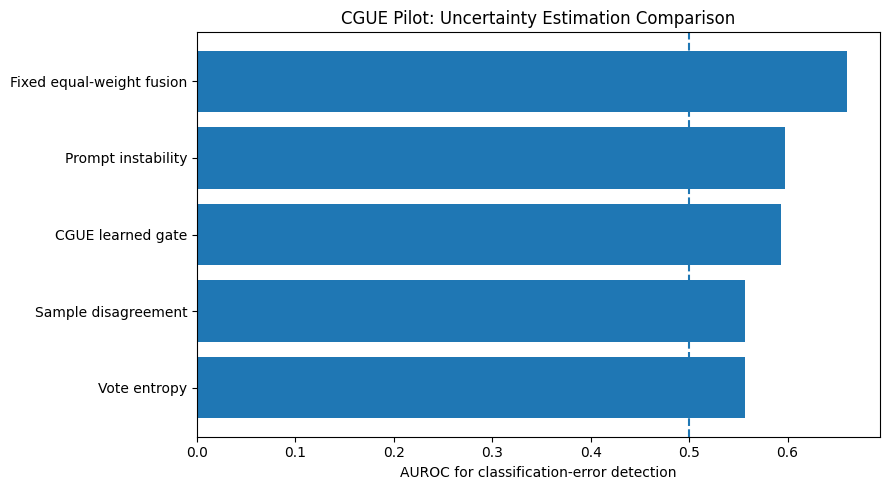

In [ ]:
import matplotlib.pyplot as plt

plot_data = results.sort_values("AUROC", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(plot_data["Method"], plot_data["AUROC"])
plt.axvline(0.5, linestyle="--")
plt.xlabel("AUROC for classification-error detection")
plt.title("CGUE Pilot: Uncertainty Estimation Comparison")
plt.tight_layout()
plt.savefig("cgue_pilot_auroc.png", dpi=200)
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np
import pandas as pd

# Fit alternative gates using training data only.
candidates = {
    "Logistic regression": LogisticRegression(
        C=0.1,
        class_weight=None,
        max_iter=2000,
        random_state=SEED
    ),
    "Small regularized MLP": MLPClassifier(
        hidden_layer_sizes=(4,),
        alpha=0.1,
        max_iter=1500,
        early_stopping=False,
        random_state=SEED
    )
}

candidate_models = {}
validation_results = []

for name, clf in candidates.items():
    clf.fit(X_train_scaled, y_train)
    candidate_models[name] = clf

    val_scores = clf.predict_proba(X_val_scaled)[:, 1]

    validation_results.append({
        "Method": name,
        "Validation AUROC": (
            roc_auc_score(y_val, val_scores)
            if len(np.unique(y_val)) > 1 else np.nan
        ),
        "Validation AUPRC": average_precision_score(
            y_val, val_scores
        )
    })

# Fixed fusion, with scaling parameters learned from training data.
val_fixed_fusion = (
    (X_val - fusion_mean) / fusion_std
).mean(axis=1)

validation_results.append({
    "Method": "Fixed equal-weight fusion",
    "Validation AUROC": (
        roc_auc_score(y_val, val_fixed_fusion)
        if len(np.unique(y_val)) > 1 else np.nan
    ),
    "Validation AUPRC": average_precision_score(
        y_val, val_fixed_fusion
    )
})

validation_table = pd.DataFrame(validation_results)
print(validation_table.to_string(index=False))

# Examine whether uncertainty features have useful relationships
# with the classification-error target.
diagnostics = train_features[FEATURES + ["is_error"]].corr()

print("\nTraining feature correlations:")
print(diagnostics.round(3).to_string())

                   Method  Validation AUROC  Validation AUPRC
      Logistic regression          0.694712          0.635841
    Small regularized MLP          0.682349          0.600822
Fixed equal-weight fusion          0.685783          0.614976

Training feature correlations:
                     vote_entropy  sample_disagreement  prompt_instability  invalid_rate  is_error
vote_entropy                1.000                0.988              -0.024         0.648     0.253
sample_disagreement         0.988                1.000              -0.045         0.728     0.246
prompt_instability         -0.024               -0.045               1.000        -0.120     0.187
invalid_rate                0.648                0.728              -0.120         1.000     0.249
is_error                    0.253                0.246               0.187         0.249     1.000


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

FEATURE_SETS = {
    "All four features": [
        "vote_entropy", "sample_disagreement",
        "prompt_instability", "invalid_rate"
    ],
    "Remove sample disagreement": [
        "vote_entropy", "prompt_instability", "invalid_rate"
    ],
    "Remove vote entropy": [
        "sample_disagreement", "prompt_instability", "invalid_rate"
    ],
    "Prompt + invalid rate": [
        "prompt_instability", "invalid_rate"
    ],
    "Prompt instability only": [
        "prompt_instability"
    ]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
models = {}

for name, features in FEATURE_SETS.items():
    X = train_features[features].to_numpy()
    y = train_features["is_error"].to_numpy()

    pipe = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=0.1, max_iter=2000, random_state=SEED)
    )

    scores = cross_validate(
        pipe, X, y, cv=cv,
        scoring={
            "auroc": "roc_auc",
            "auprc": "average_precision"
        },
        return_train_score=False
    )

    # Fit on the full training partition and evaluate on validation.
    pipe.fit(X, y)
    val_scores = pipe.predict_proba(
        val_features[features].to_numpy()
    )[:, 1]

    models[name] = (pipe, features)

    rows.append({
        "Feature set": name,
        "CV AUROC mean": scores["test_auroc"].mean(),
        "CV AUROC SD": scores["test_auroc"].std(),
        "CV AUPRC mean": scores["test_auprc"].mean(),
        "Validation AUROC": roc_auc_score(
            y_val, val_scores
        ) if len(np.unique(y_val)) > 1 else np.nan,
        "Validation AUPRC": average_precision_score(
            y_val, val_scores
        )
    })

ablation_results = pd.DataFrame(rows).sort_values(
    "CV AUROC mean", ascending=False
)

print(ablation_results.round(4).to_string(index=False))
ablation_results.to_csv("cgue_feature_ablation.csv", index=False)

               Feature set  CV AUROC mean  CV AUROC SD  CV AUPRC mean  Validation AUROC  Validation AUPRC
Remove sample disagreement         0.6889       0.0699         0.6085            0.6947            0.6358
         All four features         0.6871       0.0689         0.6021            0.6947            0.6358
       Remove vote entropy         0.6871       0.0664         0.6101            0.6947            0.6358
     Prompt + invalid rate         0.6532       0.0442         0.5889            0.6758            0.5860
   Prompt instability only         0.5759       0.0435         0.5004            0.6106            0.4628


In [ ]:
# Check whether feature sets and fitted predictions actually differ.

for name, (pipe, features) in models.items():
    Xv = val_features[features].to_numpy()
    scores = pipe.predict_proba(Xv)[:, 1]

    print(f"\n{name}")
    print("Features:", features)
    print("Prediction range:",
          round(scores.min(), 4), "to", round(scores.max(), 4))
    print("First 10 probabilities:",
          np.round(scores[:10], 4).tolist())
    print("Unique probabilities:", len(np.unique(np.round(scores, 6))))
    print("Validation AUROC:",
          round(roc_auc_score(y_val, scores), 6))


All four features
Features: ['vote_entropy', 'sample_disagreement', 'prompt_instability', 'invalid_rate']
Prediction range: 0.2916 to 0.6784
First 10 probabilities: [0.2916, 0.2916, 0.4689, 0.3761, 0.5902, 0.2916, 0.2916, 0.4016, 0.2916, 0.3761]
Unique probabilities: 12
Validation AUROC: 0.694712

Remove sample disagreement
Features: ['vote_entropy', 'prompt_instability', 'invalid_rate']
Prediction range: 0.2924 to 0.6838
First 10 probabilities: [0.2924, 0.2924, 0.4701, 0.3771, 0.596, 0.2924, 0.2924, 0.4073, 0.2924, 0.3771]
Unique probabilities: 12
Validation AUROC: 0.694712

Remove vote entropy
Features: ['sample_disagreement', 'prompt_instability', 'invalid_rate']
Prediction range: 0.2957 to 0.686
First 10 probabilities: [0.2957, 0.2957, 0.4754, 0.3815, 0.5979, 0.2957, 0.2957, 0.4079, 0.2957, 0.3815]
Unique probabilities: 12
Validation AUROC: 0.694712

Prompt + invalid rate
Features: ['prompt_instability', 'invalid_rate']
Prediction range: 0.3061 to 0.7573
First 10 probabilities: [0

In [ ]:
import numpy as np
import pandas as pd
import torch

from scipy.special import softmax

def score_candidate_labels(dataframe, batch_size=8):
    records = []

    for article in dataframe["text"].tolist():
        prompt = make_chat_prompt(PROMPTS[0], article)
        prefix_ids = tokenizer(
            prompt, add_special_tokens=False
        )["input_ids"]

        candidate_sequences = []
        candidate_lengths = []

        for label in LABELS:
            full_ids = tokenizer(
                prompt + label,
                add_special_tokens=False
            )["input_ids"]

            # Ensure the candidate answer begins after the prompt.
            if full_ids[:len(prefix_ids)] != prefix_ids:
                raise ValueError(
                    "Prompt tokenization boundary mismatch. "
                    "Use a tokenizer-safe continuation format."
                )

            candidate_sequences.append(full_ids)
            candidate_lengths.append(
                len(full_ids) - len(prefix_ids)
            )

        scores = []

        # Score each class continuation by mean token log-likelihood.
        for start in range(0, len(candidate_sequences), batch_size):
            seqs = candidate_sequences[start:start + batch_size]
            lengths = candidate_lengths[start:start + batch_size]

            max_len = max(map(len, seqs))
            input_ids = torch.full(
                (len(seqs), max_len),
                tokenizer.pad_token_id,
                dtype=torch.long,
                device=model.device
            )
            attention_mask = torch.zeros_like(input_ids)

            for j, seq in enumerate(seqs):
                input_ids[j, :len(seq)] = torch.tensor(
                    seq, dtype=torch.long, device=model.device
                )
                attention_mask[j, :len(seq)] = 1

            with torch.inference_mode():
                logits = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                ).logits.float()

            for j, seq in enumerate(seqs):
                prefix_len = len(prefix_ids)
                answer_len = lengths[j]

                # Logits at position t predict token t+1.
                positions = torch.arange(
                    prefix_len - 1,
                    prefix_len + answer_len - 1,
                    device=model.device
                )
                targets = input_ids[
                    j, prefix_len:prefix_len + answer_len
                ]

                log_probs = torch.log_softmax(
                    logits[j, positions, :], dim=-1
                )
                token_log_probs = log_probs.gather(
                    1, targets.unsqueeze(1)
                ).squeeze(1)

                scores.append(
                    token_log_probs.mean().item()
                )

            del input_ids, attention_mask, logits

        scores = np.asarray(scores, dtype=float)
        class_probs = softmax(scores)

        sorted_scores = np.sort(scores)
        margin = sorted_scores[-1] - sorted_scores[-2]

        entropy = -np.sum(
            class_probs * np.log(class_probs + 1e-12)
        ) / np.log(len(LABELS))

        records.append({
            "likelihood_entropy": float(entropy),
            "likelihood_margin": float(margin),
            "likelihood_pred": int(np.argmax(scores))
        })

    return pd.DataFrame(records)


# Compute likelihood features separately for each partition.
train_likelihood = score_candidate_labels(train_df)
val_likelihood = score_candidate_labels(val_df)
test_likelihood = score_candidate_labels(test_df)

train_likelihood.to_csv("cgue_train_likelihood.csv", index=False)
val_likelihood.to_csv("cgue_validation_likelihood.csv", index=False)
test_likelihood.to_csv("cgue_test_likelihood.csv", index=False)

print("Likelihood feature extraction completed.")
print(test_likelihood.describe().round(4))

Likelihood feature extraction completed.
       likelihood_entropy  likelihood_margin  likelihood_pred
count             80.0000            80.0000          80.0000
mean               0.3000             2.6320           0.9375
std                0.2229             1.6158           1.0106
min                0.0085             0.1406           0.0000
25%                0.0938             1.2266           0.0000
50%                0.2587             2.4724           1.0000
75%                0.4900             3.7367           2.0000
max                0.7877             6.7211           3.0000


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

BASE_FEATURES = [
    "vote_entropy",
    "prompt_instability",
    "invalid_rate"
]

def combine_features(base, likelihood):
    out = base[BASE_FEATURES].reset_index(drop=True).copy()
    likelihood = likelihood.reset_index(drop=True)

    out["likelihood_entropy"] = likelihood["likelihood_entropy"]
    out["likelihood_margin"] = likelihood["likelihood_margin"]
    return out

train_expanded = combine_features(train_features, train_likelihood)
val_expanded = combine_features(val_features, val_likelihood)
test_expanded = combine_features(test_features, test_likelihood)

EXPANDED_FEATURES = list(train_expanded.columns)

def fit_and_evaluate(train_x, val_x, test_x, y_train, y_val, y_test):
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=0.1, max_iter=2000, random_state=SEED)
    )
    model.fit(train_x, y_train)

    val_scores = model.predict_proba(val_x)[:, 1]
    test_scores = model.predict_proba(test_x)[:, 1]

    return model, {
        "Validation AUROC": roc_auc_score(y_val, val_scores),
        "Validation AUPRC": average_precision_score(y_val, val_scores),
        "Test AUROC": roc_auc_score(y_test, test_scores),
        "Test AUPRC": average_precision_score(y_test, test_scores)
    }

# Compare the compact consistency model with the expanded model.
compact_model, compact_results = fit_and_evaluate(
    train_features[BASE_FEATURES].to_numpy(),
    val_features[BASE_FEATURES].to_numpy(),
    test_features[BASE_FEATURES].to_numpy(),
    y_train, y_val, y_test
)

expanded_model, expanded_results = fit_and_evaluate(
    train_expanded.to_numpy(),
    val_expanded.to_numpy(),
    test_expanded.to_numpy(),
    y_train, y_val, y_test
)

comparison = pd.DataFrame([
    {"Model": "Consistency features", **compact_results},
    {"Model": "Consistency + likelihood", **expanded_results}
])

print(comparison.round(4).to_string(index=False))
comparison.to_csv("cgue_likelihood_comparison.csv", index=False)

                   Model  Validation AUROC  Validation AUPRC  Test AUROC  Test AUPRC
    Consistency features            0.6947            0.6358      0.6562      0.5122
Consistency + likelihood            0.8523            0.7758      0.7133      0.5660


In [ ]:
from datasets import load_dataset
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

SEED = 123

# Official AG News training and test splits
ag_train = load_dataset("fancyzhx/ag_news", split="train").to_pandas()
ag_test = load_dataset("fancyzhx/ag_news", split="test").to_pandas()

ag_train = ag_train[["text", "label"]]
ag_test = ag_test[["text", "label"]]

# Sample training data independently of the official test set
development, _ = train_test_split(
    ag_train,
    train_size=1600,
    random_state=SEED,
    stratify=ag_train["label"]
)

train_df, val_df = train_test_split(
    development,
    test_size=0.25,
    random_state=SEED,
    stratify=development["label"]
)

# Reserve this official test sample for the final evaluation
test_df, _ = train_test_split(
    ag_test,
    train_size=500,
    random_state=SEED,
    stratify=ag_test["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Fresh official test:", len(test_df))

Training: 1200
Validation: 400
Fresh official test: 500


In [ ]:
train_features = extract_features(train_df, "large_train")
val_features = extract_features(val_df, "large_validation")
test_features = extract_features(test_df, "official_test")

train_likelihood = score_candidate_labels(train_df)
val_likelihood = score_candidate_labels(val_df)
test_likelihood = score_candidate_labels(test_df)

train_likelihood.to_csv("large_train_likelihood.csv", index=False)
val_likelihood.to_csv("large_validation_likelihood.csv", index=False)
test_likelihood.to_csv("official_test_likelihood.csv", index=False)

print("All feature files saved.")

All feature files saved.


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

BASE_FEATURES = [
    "vote_entropy",
    "prompt_instability",
    "invalid_rate"
]

def combine_features(base, likelihood):
    out = base[BASE_FEATURES].reset_index(drop=True).copy()
    likelihood = likelihood.reset_index(drop=True)

    out["likelihood_entropy"] = likelihood["likelihood_entropy"]
    out["likelihood_margin"] = likelihood["likelihood_margin"]
    return out

train_x = combine_features(train_features, train_likelihood)
val_x = combine_features(val_features, val_likelihood)
test_x = combine_features(test_features, test_likelihood)

y_train = train_features["is_error"].to_numpy()
y_val = val_features["is_error"].to_numpy()
y_test = test_features["is_error"].to_numpy()

def evaluate_model(train_data, val_data, test_data):
    clf = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=0.1, max_iter=2000, random_state=SEED)
    )
    clf.fit(train_data, y_train)

    val_prob = clf.predict_proba(val_data)[:, 1]
    test_prob = clf.predict_proba(test_data)[:, 1]

    return clf, {
        "Validation AUROC": roc_auc_score(y_val, val_prob),
        "Validation AUPRC": average_precision_score(y_val, val_prob),
        "Test AUROC": roc_auc_score(y_test, test_prob),
        "Test AUPRC": average_precision_score(y_test, test_prob)
    }

compact_model, compact_metrics = evaluate_model(
    train_x[BASE_FEATURES].to_numpy(),
    val_x[BASE_FEATURES].to_numpy(),
    test_x[BASE_FEATURES].to_numpy()
)

expanded_features = BASE_FEATURES + [
    "likelihood_entropy", "likelihood_margin"
]

expanded_model, expanded_metrics = evaluate_model(
    train_x[expanded_features].to_numpy(),
    val_x[expanded_features].to_numpy(),
    test_x[expanded_features].to_numpy()
)

comparison = pd.DataFrame([
    {"Model": "Consistency only", **compact_metrics},
    {"Model": "Consistency + likelihood", **expanded_metrics}
])

print(comparison.round(4).to_string(index=False))
comparison.to_csv("cgue_large_evaluation.csv", index=False)

                   Model  Validation AUROC  Validation AUPRC  Test AUROC  Test AUPRC
        Consistency only            0.6197            0.5183      0.6317      0.5247
Consistency + likelihood            0.7314            0.6505      0.7697      0.6593


In [ ]:
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

rng = np.random.default_rng(123)
N_BOOT = 2000

CONSISTENCY = BASE_FEATURES
LIKELIHOOD = ["likelihood_entropy", "likelihood_margin"]
ALL_FEATURES = CONSISTENCY + LIKELIHOOD

def fit_gate(features):
    clf = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=0.1, max_iter=2000, random_state=SEED)
    )
    clf.fit(train_x[features], y_train)
    return (
        clf.predict_proba(val_x[features])[:, 1],
        clf.predict_proba(test_x[features])[:, 1]
    )

# Fit baseline models using training data only.
val_cons, test_cons = fit_gate(CONSISTENCY)
val_like, test_like = fit_gate(LIKELIHOOD)
val_full, test_full = fit_gate(ALL_FEATURES)

# Equal-weight fusion: normalize each feature using training statistics.
mu = train_x[ALL_FEATURES].mean(axis=0)
sd = train_x[ALL_FEATURES].std(axis=0).replace(0, 1)

fixed_val = (
    (val_x[ALL_FEATURES] - mu) / sd
).mean(axis=1).to_numpy()

fixed_test = (
    (test_x[ALL_FEATURES] - mu) / sd
).mean(axis=1).to_numpy()

predictions = {
    "Consistency only": test_cons,
    "Likelihood only": test_like,
    "Fixed equal-weight fusion": fixed_test,
    "Learned consistency + likelihood": test_full
}

# Use paired bootstrap samples for all methods.
# Resample test examples, retaining the same sampled indices per method.
valid_indices = np.arange(len(y_test))
boot_results = {name: [] for name in predictions}
boot_deltas = []

for _ in range(N_BOOT):
    idx = rng.choice(valid_indices, size=len(valid_indices), replace=True)

    if len(np.unique(y_test[idx])) < 2:
        continue

    aucs = {}
    for name, scores in predictions.items():
        aucs[name] = roc_auc_score(y_test[idx], scores[idx])
        boot_results[name].append(aucs[name])

    boot_deltas.append(
        aucs["Learned consistency + likelihood"]
        - aucs["Consistency only"]
    )

rows = []
for name, scores in predictions.items():
    auc = roc_auc_score(y_test, scores)
    auprc = average_precision_score(y_test, scores)
    lo, hi = np.percentile(boot_results[name], [2.5, 97.5])

    rows.append({
        "Method": name,
        "Test AUROC": auc,
        "AUROC 95% CI lower": lo,
        "AUROC 95% CI upper": hi,
        "Test AUPRC": auprc
    })

final_table = pd.DataFrame(rows)
print(final_table.round(4).to_string(index=False))

delta_lo, delta_hi = np.percentile(boot_deltas, [2.5, 97.5])

print("\nPaired bootstrap AUROC difference:")
print("Learned fusion - consistency only:",
      round(roc_auc_score(y_test, test_full)
            - roc_auc_score(y_test, test_cons), 4))
print("95% bootstrap CI:", (round(delta_lo, 4), round(delta_hi, 4)))

final_table.to_csv("cgue_final_baselines.csv", index=False)

                          Method  Test AUROC  AUROC 95% CI lower  AUROC 95% CI upper  Test AUPRC
                Consistency only      0.6317              0.5853              0.6779      0.5247
                 Likelihood only      0.7711              0.7283              0.8149      0.6631
       Fixed equal-weight fusion      0.6270              0.5749              0.6781      0.5621
Learned consistency + likelihood      0.7697              0.7262              0.8106      0.6593

Paired bootstrap AUROC difference:
Learned fusion - consistency only: 0.1379
95% bootstrap CI: (np.float64(0.0968), np.float64(0.1784))


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

rng = np.random.default_rng(2026)
N_BOOT = 5000

y = np.asarray(y_test)
scores_likelihood = np.asarray(test_like)
scores_combined = np.asarray(test_full)

delta_auc = []
delta_ap = []

for _ in range(N_BOOT):
    idx = rng.integers(0, len(y), size=len(y))

    if len(np.unique(y[idx])) < 2:
        continue

    auc_l = roc_auc_score(y[idx], scores_likelihood[idx])
    auc_c = roc_auc_score(y[idx], scores_combined[idx])

    ap_l = average_precision_score(y[idx], scores_likelihood[idx])
    ap_c = average_precision_score(y[idx], scores_combined[idx])

    delta_auc.append(auc_c - auc_l)
    delta_ap.append(ap_c - ap_l)

def summarize_difference(values):
    values = np.asarray(values)
    return {
        "Mean bootstrap difference": values.mean(),
        "95% CI lower": np.percentile(values, 2.5),
        "95% CI upper": np.percentile(values, 97.5)
    }

print("Combined minus likelihood-only — AUROC")
print(summarize_difference(delta_auc))

print("\nCombined minus likelihood-only — AUPRC")
print(summarize_difference(delta_ap))

print("\nObserved AUROC difference:",
      roc_auc_score(y, scores_combined)
      - roc_auc_score(y, scores_likelihood))

print("Observed AUPRC difference:",
      average_precision_score(y, scores_combined)
      - average_precision_score(y, scores_likelihood))

Combined minus likelihood-only — AUROC
{'Mean bootstrap difference': np.float64(-0.0015187164796994492), '95% CI lower': np.float64(-0.015083586584233139), '95% CI upper': np.float64(0.012504502766067746)}

Combined minus likelihood-only — AUPRC
{'Mean bootstrap difference': np.float64(-0.0063355191968298185), '95% CI lower': np.float64(-0.03834134972798004), '95% CI upper': np.float64(0.02499863146910972)}

Observed AUROC difference: -0.001485834488054838
Observed AUPRC difference: -0.0037365392483484916


In [ ]:
from pathlib import Path
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

SEED = 123
rng = np.random.default_rng(SEED)

OUT = Path("cgue_final_results")
FIG = OUT / "figures"
TAB = OUT / "tables"

FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

y_train = np.asarray(y_train, dtype=int)
y_val = np.asarray(y_val, dtype=int)
y_test = np.asarray(y_test, dtype=int)

assert len(y_test) == len(test_features)
assert len(test_like) == len(y_test)
assert len(test_full) == len(y_test)
assert len(fixed_test) == len(y_test)

print("Output folder:", OUT.resolve())
print("Training / validation / test:", len(y_train), len(y_val), len(y_test))
print("Test error prevalence:", round(y_test.mean(), 4))

Output folder: /content/cgue_final_results
Training / validation / test: 1200 400 500
Test error prevalence: 0.398


In [ ]:
from sklearn.dummy import DummyClassifier

N_BOOT = 5000

predictions = {
    "Consistency only": np.asarray(test_cons),
    "Likelihood only": np.asarray(test_like),
    "Fixed equal-weight fusion": np.asarray(fixed_test),
    "Learned consistency + likelihood": np.asarray(test_full)
}

def auc_ap(y, score):
    return (
        roc_auc_score(y, score),
        average_precision_score(y, score)
    )

def paired_bootstrap_metrics(y, prediction_dict, n_boot=5000, seed=123):
    rng = np.random.default_rng(seed)
    names = list(prediction_dict)
    samples = {name: [] for name in names}
    delta = {}

    for _ in range(n_boot):
        idx = rng.integers(0, len(y), size=len(y))
        if np.unique(y[idx]).size < 2:
            continue

        vals = {}
        for name, scores in prediction_dict.items():
            auc, ap = auc_ap(y[idx], scores[idx])
            samples[name].append((auc, ap))
            vals[name] = (auc, ap)

        pairs = [
            ("Learned consistency + likelihood", "Likelihood only"),
            ("Learned consistency + likelihood", "Consistency only"),
            ("Learned consistency + likelihood", "Fixed equal-weight fusion")
        ]

        for a, b in pairs:
            key = f"{a} minus {b}"
            delta.setdefault(key, []).append(
                np.array(vals[a]) - np.array(vals[b])
            )

    rows = []
    for name, scores in prediction_dict.items():
        auc, ap = auc_ap(y, scores)
        arr = np.asarray(samples[name])

        rows.append({
            "Method": name,
            "Test AUROC": auc,
            "AUROC CI lower": np.quantile(arr[:, 0], .025),
            "AUROC CI upper": np.quantile(arr[:, 0], .975),
            "Test AUPRC": ap,
            "AUPRC CI lower": np.quantile(arr[:, 1], .025),
            "AUPRC CI upper": np.quantile(arr[:, 1], .975)
        })

    delta_rows = []
    for key, values in delta.items():
        arr = np.asarray(values)
        delta_rows.append({
            "Comparison": key,
            "AUROC difference": arr[:, 0].mean(),
            "AUROC difference CI lower": np.quantile(arr[:, 0], .025),
            "AUROC difference CI upper": np.quantile(arr[:, 0], .975),
            "AUPRC difference": arr[:, 1].mean(),
            "AUPRC difference CI lower": np.quantile(arr[:, 1], .025),
            "AUPRC difference CI upper": np.quantile(arr[:, 1], .975)
        })

    return pd.DataFrame(rows), pd.DataFrame(delta_rows)

main_table, paired_table = paired_bootstrap_metrics(
    y_test, predictions, N_BOOT, SEED
)

main_table.to_csv(TAB / "table_main_comparison.csv", index=False)
paired_table.to_csv(TAB / "table_paired_bootstrap.csv", index=False)

print(main_table.round(4).to_string(index=False))
print("\nPaired comparisons")
print(paired_table.round(4).to_string(index=False))
print("\nAUPRC reference prevalence:", round(y_test.mean(), 4))

                          Method  Test AUROC  AUROC CI lower  AUROC CI upper  Test AUPRC  AUPRC CI lower  AUPRC CI upper
                Consistency only      0.6317          0.5849          0.6798      0.5247          0.4624          0.5960
                 Likelihood only      0.7711          0.7284          0.8133      0.6631          0.5946          0.7431
       Fixed equal-weight fusion      0.6270          0.5752          0.6814      0.5621          0.4944          0.6410
Learned consistency + likelihood      0.7697          0.7277          0.8107      0.6593          0.5907          0.7343

Paired comparisons
                                                      Comparison  AUROC difference  AUROC difference CI lower  AUROC difference CI upper  AUPRC difference  AUPRC difference CI lower  AUPRC difference CI upper
          Learned consistency + likelihood minus Likelihood only           -0.0012                    -0.0156                     0.0135           -0.0058            

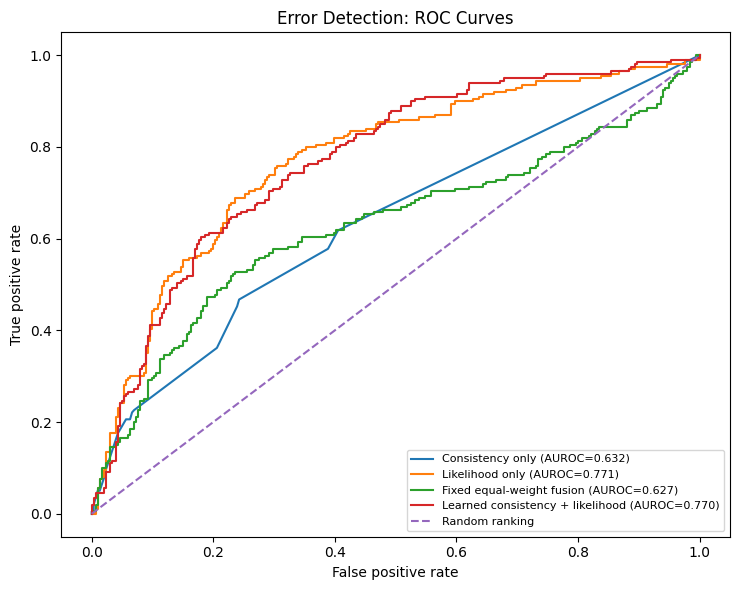

In [ ]:
plt.figure(figsize=(7.5, 6))

for name, scores in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc = roc_auc_score(y_test, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUROC={auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Error Detection: ROC Curves")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "fig1_roc_curves.png", dpi=300)
plt.show()

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
plt.figure(figsize=(7.5, 6))

for name, scores in predictions.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)
    plt.plot(recall, precision, label=f"{name} (AUPRC={ap:.3f})")

plt.axhline(y_test.mean(), linestyle="--", label="Prevalence baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Error Detection: Precision–Recall Curves")
plt.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "fig2_precision_recall.png", dpi=300)
plt.savefig(FIG / "fig2_precision_recall.pdf")
plt.show()

NameError: name 'predictions' is not defined

<Figure size 750x600 with 0 Axes>

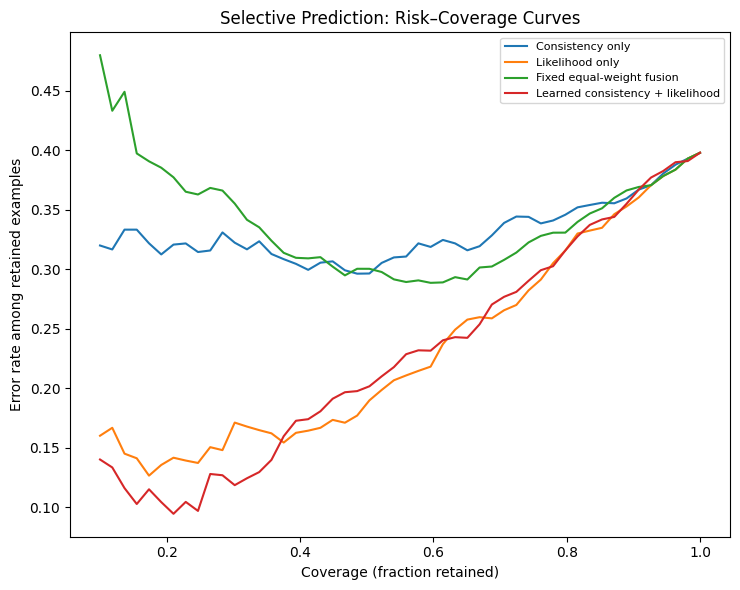

                          Method  Risk at 80% coverage  Risk at 90% coverage  Risk at 95% coverage  Risk at 100% coverage
                Consistency only                0.3450                0.3644                0.3811                  0.398
                 Likelihood only                0.3175                0.3578                0.3789                  0.398
       Fixed equal-weight fusion                0.3325                0.3689                0.3768                  0.398
Learned consistency + likelihood                0.3150                0.3600                0.3811                  0.398


In [ ]:
def risk_coverage(y, error_scores, n_points=50):
    order = np.argsort(error_scores)
    y_ordered = y[order]

    coverages = np.linspace(0.1, 1.0, n_points)
    risks = []

    for coverage in coverages:
        n = max(1, int(np.ceil(coverage * len(y_ordered))))
        risks.append(y_ordered[:n].mean())

    return coverages, np.asarray(risks)

rc_rows = []

plt.figure(figsize=(7.5, 6))

for name, scores in predictions.items():
    coverage, risk = risk_coverage(y_test, scores)
    plt.plot(coverage, risk, label=name)

    for c, r in zip(coverage, risk):
        rc_rows.append({
            "Method": name,
            "Coverage": c,
            "Selective risk": r
        })

plt.xlabel("Coverage (fraction retained)")
plt.ylabel("Error rate among retained examples")
plt.title("Selective Prediction: Risk–Coverage Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "fig3_risk_coverage.png", dpi=300)
# Removed PDF export to bypass Python 3.13 Matplotlib backend FontPath import bug
plt.show()

rc_df = pd.DataFrame(rc_rows)
rc_df.to_csv(TAB / "table_risk_coverage_curve.csv", index=False)

summary = []
for name, scores in predictions.items():
    row = {"Method": name}

    for coverage_target in [0.80, 0.90, 0.95, 1.00]:
        n = max(1, int(np.ceil(coverage_target * len(y_test))))
        order = np.argsort(scores)
        row[f"Risk at {coverage_target:.0%} coverage"] = (
            y_test[order[:n]].mean()
        )

    summary.append(row)

risk_summary = pd.DataFrame(summary)
risk_summary.to_csv(TAB / "table_risk_at_coverage.csv", index=False)
print(risk_summary.round(4).to_string(index=False))

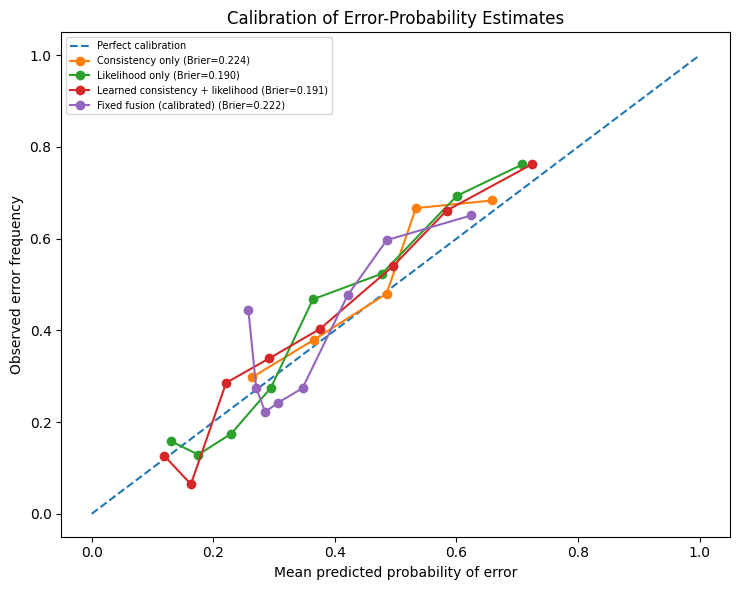

                          Method  Brier score  ECE (10 bins)
                Consistency only       0.2238         0.0289
                 Likelihood only       0.1895         0.0506
Learned consistency + likelihood       0.1911         0.0513
       Fixed fusion (calibrated)       0.2217         0.0632


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def expected_calibration_error(y, probabilities, n_bins=10):
    y = np.asarray(y)
    probabilities = np.asarray(probabilities)

    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (
                (probabilities >= edges[i]) &
                (probabilities <= edges[i + 1])
            )
        else:
            mask = (
                (probabilities >= edges[i]) &
                (probabilities < edges[i + 1])
            )

        if mask.any():
            ece += mask.mean() * abs(
                y[mask].mean() - probabilities[mask].mean()
            )

    return ece


# Fit a calibration mapping for the fixed-fusion score.
# The calibration model uses training data only.
mu = train_x[ALL_FEATURES].mean(axis=0)
sd = train_x[ALL_FEATURES].std(axis=0).replace(0, 1)

train_fixed_score = (
    (train_x[ALL_FEATURES] - mu) / sd
).mean(axis=1).to_numpy().reshape(-1, 1)

val_fixed_score = (
    (val_x[ALL_FEATURES] - mu) / sd
).mean(axis=1).to_numpy().reshape(-1, 1)

test_fixed_score = (
    (test_x[ALL_FEATURES] - mu) / sd
).mean(axis=1).to_numpy().reshape(-1, 1)

fixed_calibrator = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=0.1, max_iter=2000, random_state=SEED)
)
fixed_calibrator.fit(train_fixed_score, y_train)

# Use calibrated probabilities for the calibration figure.
probability_predictions = {
    "Consistency only": np.asarray(test_cons),
    "Likelihood only": np.asarray(test_like),
    "Learned consistency + likelihood": np.asarray(test_full),
    "Fixed fusion (calibrated)": fixed_calibrator.predict_proba(
        test_fixed_score
    )[:, 1]
}

# Validate all inputs before calculating calibration metrics.
for name, probabilities in probability_predictions.items():
    assert np.all(np.isfinite(probabilities)), f"Non-finite values in {name}"
    assert np.all((probabilities >= 0) & (probabilities <= 1)), (
        f"Invalid probabilities in {name}"
    )

calibration_rows = []

plt.figure(figsize=(7.5, 6))
plt.plot(
    [0, 1], [0, 1],
    linestyle="--", label="Perfect calibration"
)

for name, probabilities in probability_predictions.items():
    frac_positive, mean_predicted = calibration_curve(
        y_test,
        probabilities,
        n_bins=8,
        strategy="quantile"
    )

    brier = brier_score_loss(y_test, probabilities)
    ece = expected_calibration_error(
        y_test, probabilities, n_bins=10
    )

    plt.plot(
        mean_predicted,
        frac_positive,
        marker="o",
        label=f"{name} (Brier={brier:.3f})"
    )

    calibration_rows.append({
        "Method": name,
        "Brier score": brier,
        "ECE (10 bins)": ece
    })

plt.xlabel("Mean predicted probability of error")
plt.ylabel("Observed error frequency")
plt.title("Calibration of Error-Probability Estimates")
plt.legend(fontsize=7)
plt.tight_layout()
plt.savefig(FIG / "fig4_calibration.png", dpi=300)
plt.show()

calibration_table = pd.DataFrame(calibration_rows)
calibration_table.to_csv(
    TAB / "table_calibration.csv", index=False
)

print(calibration_table.round(4).to_string(index=False))

                    Feature set  CV AUROC mean  CV AUROC SD  CV AUPRC mean  Validation AUROC  Validation AUPRC
                Likelihood only         0.7525       0.0355         0.6433            0.7260            0.6466
               Consistency only         0.6658       0.0152         0.5533            0.6197            0.5183
Likelihood + prompt instability         0.7579       0.0327         0.6618            0.7261            0.6431
      Likelihood + vote entropy         0.7517       0.0366         0.6379            0.7285            0.6498
              All five features         0.7587       0.0334         0.6567            0.7314            0.6505


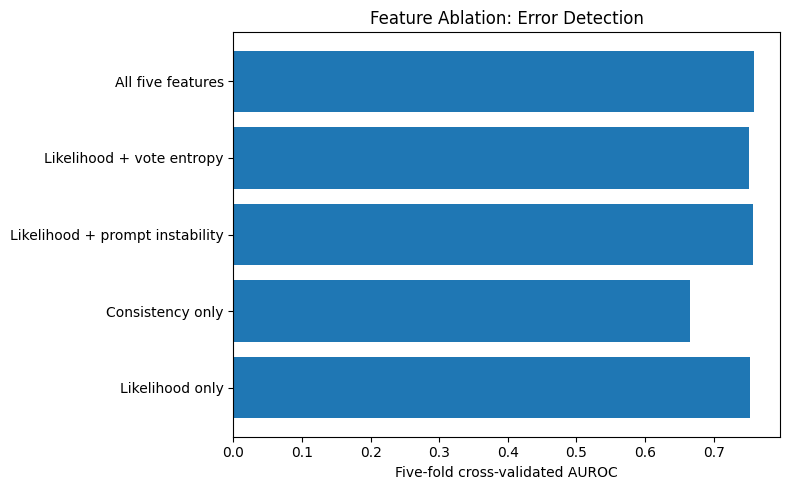

In [ ]:
FEATURE_SETS = {
    "Likelihood only": [
        "likelihood_entropy", "likelihood_margin"
    ],
    "Consistency only": [
        "vote_entropy", "prompt_instability", "invalid_rate"
    ],
    "Likelihood + prompt instability": [
        "likelihood_entropy", "likelihood_margin",
        "prompt_instability"
    ],
    "Likelihood + vote entropy": [
        "likelihood_entropy", "likelihood_margin",
        "vote_entropy"
    ],
    "All five features": [
        "vote_entropy", "prompt_instability", "invalid_rate",
        "likelihood_entropy", "likelihood_margin"
    ]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
ablation_rows = []

for name, cols in FEATURE_SETS.items():
    clf = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=0.1, max_iter=2000, random_state=SEED)
    )

    cv_scores = cross_validate(
        clf, train_x[cols], y_train, cv=cv,
        scoring={"auroc": "roc_auc", "auprc": "average_precision"}
    )

    clf.fit(train_x[cols], y_train)
    val_scores = clf.predict_proba(val_x[cols])[:, 1]

    ablation_rows.append({
        "Feature set": name,
        "CV AUROC mean": cv_scores["test_auroc"].mean(),
        "CV AUROC SD": cv_scores["test_auroc"].std(),
        "CV AUPRC mean": cv_scores["test_auprc"].mean(),
        "Validation AUROC": roc_auc_score(y_val, val_scores),
        "Validation AUPRC": average_precision_score(y_val, val_scores)
    })

ablation_table = pd.DataFrame(ablation_rows)
ablation_table.to_csv(TAB / "table_feature_ablation.csv", index=False)
print(ablation_table.round(4).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(ablation_table["Feature set"], ablation_table["CV AUROC mean"])
plt.xlabel("Five-fold cross-validated AUROC")
plt.title("Feature Ablation: Error Detection")
plt.tight_layout()
plt.savefig(FIG / "fig5_feature_ablation.png", dpi=300)
plt.show()

In [ ]:
class_names = ["World", "Sports", "Business", "Sci/Tech"]
gold_classes = test_features["gold_label"].to_numpy()

class_rows = []

for class_id, class_name in enumerate(class_names):
    mask = gold_classes == class_id
    y_class = y_test[mask]

    row = {
        "Gold class": class_name,
        "N": int(mask.sum()),
        "Error prevalence": float(y_class.mean()) if len(y_class) else np.nan
    }

    for method, scores in predictions.items():
        s = scores[mask]
        row[f"{method} AUROC"] = (
            roc_auc_score(y_class, s)
            if len(np.unique(y_class)) == 2 else np.nan
        )

    class_rows.append(row)

class_table = pd.DataFrame(class_rows)
class_table.to_csv(TAB / "table_classwise_error_detection.csv", index=False)
print(class_table.round(4).to_string(index=False))

Gold class   N  Error prevalence  Consistency only AUROC  Likelihood only AUROC  Fixed equal-weight fusion AUROC  Learned consistency + likelihood AUROC
     World 125             0.048                  0.7703                 0.9482                           0.7059                                  0.9286
    Sports 125             0.344                  0.3712                 0.7388                           0.4870                                  0.6305
  Business 125             0.376                  0.8871                 0.4572                           0.8502                                  0.6023
  Sci/Tech 125             0.824                  0.3590                 0.8036                           0.3703                                  0.7317


 Original generations  Alternative prompts  AUROC of raw score  AUPRC of raw score
                    1                    1              0.6022              0.4680
                    1                    2              0.5558              0.4211
                    1                    3              0.5717              0.4301
                    2                    1              0.6087              0.4688
                    2                    2              0.5969              0.4682
                    2                    3              0.5972              0.4812
                    3                    1              0.6162              0.4715
                    3                    2              0.6017              0.4686
                    3                    3              0.6220              0.5143


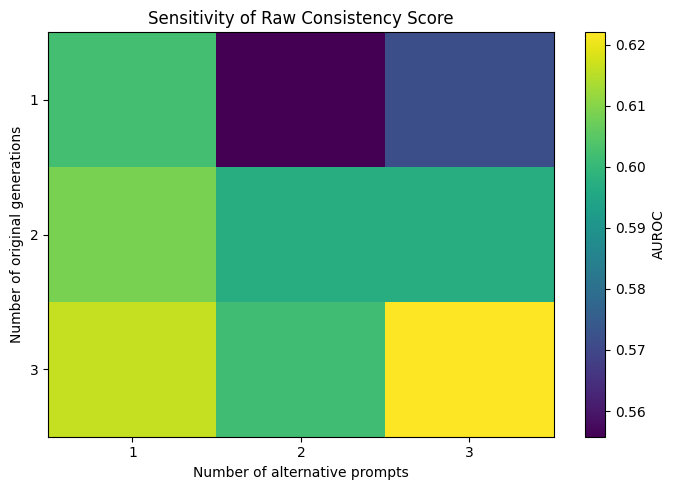

In [ ]:
from scipy.stats import entropy

def parse_prediction_list(value):
    return [int(x) for x in str(value).split(",")]

def entropy_from_predictions(preds):
    valid = np.asarray(preds)
    valid = valid[valid >= 0]

    if len(valid) == 0:
        return 1.0

    counts = np.bincount(valid, minlength=4)
    p = counts[counts > 0] / len(valid)
    return float(entropy(p) / np.log(4))

sensitivity_rows = []

for n_gen in [1, 2, 3]:
    for n_prompt in [1, 2, 3]:
        raw_scores = []
        valid_y = []

        for _, row in test_features.iterrows():
            original = parse_prediction_list(row["original_predictions"])
            variants = parse_prediction_list(row["variant_predictions"])

            sampled = original[:n_gen]
            selected_variants = variants[:n_prompt]

            valid_sampled = [p for p in sampled if p >= 0]
            valid_variants = [p for p in selected_variants if p >= 0]

            combined = valid_sampled + valid_variants
            if not combined:
                support = 0.0
                pred = -1
            else:
                counts = np.bincount(combined, minlength=4)
                pred = int(counts.argmax())
                support = counts.max() / len(combined)

            vote_ent = entropy_from_predictions(sampled)

            if pred < 0 or not valid_variants:
                instability = 1.0
            else:
                instability = float(np.mean(
                    np.asarray(valid_variants) != pred
                ))

            # A simple, pre-defined raw score for this sensitivity check.
            raw_score = (vote_ent + instability + (1.0 - support)) / 3.0

            raw_scores.append(raw_score)
            valid_y.append(int(row["is_error"]))

        if len(np.unique(valid_y)) > 1:
            sensitivity_rows.append({
                "Original generations": n_gen,
                "Alternative prompts": n_prompt,
                "AUROC of raw score": roc_auc_score(valid_y, raw_scores),
                "AUPRC of raw score": average_precision_score(valid_y, raw_scores)
            })

sensitivity_table = pd.DataFrame(sensitivity_rows)
sensitivity_table.to_csv(TAB / "table_generation_sensitivity.csv", index=False)
print(sensitivity_table.round(4).to_string(index=False))

pivot = sensitivity_table.pivot(
    index="Original generations",
    columns="Alternative prompts",
    values="AUROC of raw score"
)

plt.figure(figsize=(7, 5))
plt.imshow(pivot.values, aspect="auto")
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xlabel("Number of alternative prompts")
plt.ylabel("Number of original generations")
plt.title("Sensitivity of Raw Consistency Score")
plt.colorbar(label="AUROC")
plt.tight_layout()
plt.savefig(FIG / "fig6_generation_sensitivity.png", dpi=300)
plt.show()

In [ ]:
from pathlib import Path

for folder in [Path("/content"), Path("/content/cgue_final_results")]:
    print(f"\nChecking: {folder}")
    if folder.exists():
        for p in list(folder.rglob("*.csv"))[:40]:
            print(" ", p)
    else:
        print("Folder not found")


Checking: /content
  /content/cgue_final_baselines.csv
  /content/cgue_feature_ablation.csv
  /content/cgue_test.csv
  /content/official_test_likelihood.csv
  /content/cgue_official_test.csv
  /content/cgue_large_evaluation.csv
  /content/large_train_likelihood.csv
  /content/large_validation_likelihood.csv
  /content/cgue_likelihood_comparison.csv
  /content/cgue_large_validation.csv
  /content/cgue_validation_likelihood.csv
  /content/cgue_validation.csv
  /content/cgue_large_train.csv
  /content/cgue_train_likelihood.csv
  /content/cgue_test_likelihood.csv
  /content/cgue_pilot_results.csv
  /content/cgue_train.csv
  /content/sample_data/mnist_train_small.csv
  /content/sample_data/mnist_test.csv
  /content/sample_data/california_housing_test.csv
  /content/sample_data/california_housing_train.csv
  /content/cgue_final_results/tables/table_paired_bootstrap.csv
  /content/cgue_final_results/tables/table_main_comparison.csv
  /content/cgue_final_results/tables/table_generation_sensit

In [ ]:
from pathlib import Path

FIG = Path("/content/cgue_final_results/figures")
TAB = Path("/content/cgue_final_results/tables")

expected_figures = [
    "fig1_roc_curves.png",
    "fig2_precision_recall.png",
    "fig3_risk_coverage.png",
    "fig4_calibration.png",
    "fig5_feature_ablation.png",
    "fig6_generation_sensitivity.png",
]

expected_tables = [
    "table_main_comparison.csv",
    "table_paired_bootstrap.csv",
    "table_feature_ablation.csv",
    "table_calibration.csv",
    "table_risk_coverage_curve.csv",
    "table_risk_at_coverage.csv",
    "table_classwise_error_detection.csv",
    "table_generation_sensitivity.csv",
]

print("FIGURES")
for name in expected_figures:
    print(("OK      " if (FIG / name).exists() else "MISSING ") + name)

print("\nTABLES")
for name in expected_tables:
    print(("OK      " if (TAB / name).exists() else "MISSING ") + name)

FIGURES
OK      fig1_roc_curves.png
OK      fig2_precision_recall.png
OK      fig3_risk_coverage.png
OK      fig4_calibration.png
OK      fig5_feature_ablation.png
OK      fig6_generation_sensitivity.png

TABLES
OK      table_main_comparison.csv
OK      table_paired_bootstrap.csv
OK      table_feature_ablation.csv
OK      table_calibration.csv
OK      table_risk_coverage_curve.csv
OK      table_risk_at_coverage.csv
OK      table_classwise_error_detection.csv
OK      table_generation_sensitivity.csv


In [ ]:
import pandas as pd
from pathlib import Path

TAB = Path("/content/cgue_final_results/tables")

tables = [
    "table_main_comparison.csv",
    "table_paired_bootstrap.csv",
    "table_feature_ablation.csv",
    "table_calibration.csv",
    "table_risk_coverage_curve.csv",
    "table_risk_at_coverage.csv",
    "table_classwise_error_detection.csv",
    "table_generation_sensitivity.csv",
]

for filename in tables:
    path = TAB / filename
    print("\n" + "=" * 90)
    print(filename)
    print("=" * 90)
    df = pd.read_csv(path)
    print(df.to_string(index=False))


table_main_comparison.csv
                          Method  Test AUROC  AUROC CI lower  AUROC CI upper  Test AUPRC  AUPRC CI lower  AUPRC CI upper
                Consistency only    0.631730        0.584894        0.679812    0.524705        0.462445        0.595974
                 Likelihood only    0.771148        0.728389        0.813270    0.663072        0.594645        0.743068
       Fixed equal-weight fusion    0.627005        0.575207        0.681430    0.562072        0.494404        0.641028
Learned consistency + likelihood    0.769662        0.727710        0.810740    0.659336        0.590657        0.734293

table_paired_bootstrap.csv
                                                      Comparison  AUROC difference  AUROC difference CI lower  AUROC difference CI upper  AUPRC difference  AUPRC difference CI lower  AUPRC difference CI upper
          Learned consistency + likelihood minus Likelihood only         -0.001209                  -0.015591                   0.0

In [ ]:
from pathlib import Path
import zipfile

root = Path("/content/cgue_final_results")
root.mkdir(parents=True, exist_ok=True)

archive = Path("/content/cgue_results_package.zip")

source_files = [
    Path("/content/cgue_final_baselines.csv"),
    Path("/content/cgue_feature_ablation.csv"),
    Path("/content/cgue_likelihood_comparison.csv"),
    Path("/content/cgue_large_evaluation.csv"),
    Path("/content/cgue_pilot_results.csv"),
    Path("/content/cgue_official_test.csv"),
]

with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ["figures", "tables"]:
        directory = root / folder
        if directory.exists():
            for file in directory.rglob("*"):
                if file.is_file():
                    z.write(file, file.relative_to(root))

    for file in source_files:
        if file.exists():
            z.write(file, f"source_csv/{file.name}")

print(f"Package created: {archive}")
print(f"Size: {archive.stat().st_size / (1024 * 1024):.2f} MB")

Package created: /content/cgue_results_package.zip
Size: 0.99 MB


In [ ]:
from google.colab import files
files.download("/content/cgue_results_package.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path
import zipfile
from google.colab import files

ROOT = Path("/content/cgue_final_results")
OUT = Path("/content/CGUE_Larger_Experiment_Results.zip")

# Primary experiment figures; exclude generation-sensitivity figure
figure_names = [
    "fig1_roc_curves.png",
    "fig2_precision_recall.png",
    "fig3_risk_coverage.png",
    "fig4_calibration.png",
    "fig5_feature_ablation.png",
]

# Primary experiment tables; exclude generation-sensitivity table
table_names = [
    "table_main_comparison.csv",
    "table_paired_bootstrap.csv",
    "table_feature_ablation.csv",
    "table_calibration.csv",
    "table_risk_coverage_curve.csv",
    "table_risk_at_coverage.csv",
    "table_classwise_error_detection.csv",
]

with zipfile.ZipFile(OUT, "w", zipfile.ZIP_DEFLATED) as z:
    for name in figure_names:
        for ext in [".png", ".pdf"]:
            p = ROOT / "figures" / (Path(name).stem + ext)
            if p.exists():
                z.write(p, f"figures/{p.name}")

    for name in table_names:
        p = ROOT / "tables" / name
        if p.exists():
            z.write(p, f"tables/{p.name}")

with zipfile.ZipFile(OUT) as z:
    print("Files included:")
    for name in z.namelist():
        print(" -", name)

files.download(str(OUT))


Files included:
 - figures/fig1_roc_curves.png
 - figures/fig2_precision_recall.png
 - figures/fig3_risk_coverage.png
 - figures/fig4_calibration.png
 - figures/fig5_feature_ablation.png
 - tables/table_main_comparison.csv
 - tables/table_paired_bootstrap.csv
 - tables/table_feature_ablation.csv
 - tables/table_calibration.csv
 - tables/table_risk_coverage_curve.csv
 - tables/table_risk_at_coverage.csv
 - tables/table_classwise_error_detection.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip -q install -U transformers accelerate bitsandbytes datasets scikit-learn pandas numpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 61.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 33.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 86.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 87.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 66.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 11.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-

In [ ]:
import gc
import torch
import pandas as pd
import numpy as np

from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"
SEED = 123

assert torch.cuda.is_available(), "Enable a GPU in Colab first."

print("GPU:", torch.cuda.get_device_name(0))
print("VRAM (GB):", round(
    torch.cuda.get_device_properties(0).total_memory / 1e9, 2
))

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16
)

model.eval()
print("Loaded:", MODEL_ID)

ModuleNotFoundError: Could not import module 'AutoTokenizer'. Are this object's requirements defined correctly? Set the logging verbosity to DEBUG for the original import error.

In [ ]:
%pip install -q --upgrade "numpy==2.2.6" "scipy>=1.15.2" "scikit-learn>=1.6" "transformers>=4.51.0" accelerate bitsandbytes datasets

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 61.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 21.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.


In [ ]:
%pip install --force-reinstall --no-cache-dir "transformers==4.51.3" "numpy==2.1.3" "scipy==1.15.3" "scikit-learn==1.6.1"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 295.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 292.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 281.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 304.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 289.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 71.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 194.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 199.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.2/13.2 MB 143.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 85.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 418.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 237.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import numpy as np
import scipy
import sklearn
import torch
import transformers

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)

from transformers import AutoTokenizer, AutoModelForCausalLM
print("SUCCESS: Transformers imports are working.")

NumPy: 2.1.3
SciPy: 1.16.3
Scikit-learn: 1.6.1
PyTorch: 2.11.0+cu130
Transformers: 5.18.0
SUCCESS: Transformers imports are working.


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"

config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=config,
    device_map="auto",
)
model.eval()

messages = [{
    "role": "user",
    "content": (
        "Classify this headline into exactly one category: "
        "World, Sports, Business, or Sci/Tech.\n"
        "Headline: Apple reports record quarterly revenue.\n"
        "Category:"
    )
}]

inputs = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_tensors="pt",
).to(model.device)

with torch.inference_mode():
    output = model.generate(
        inputs,
        max_new_tokens=20,
        do_sample=False,
    )

print(tokenizer.decode(
    output[0][inputs.shape[-1]:],
    skip_special_tokens=True,
))

PackageNotFoundError: No package metadata was found for bitsandbytes

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=config,
    device_map="auto",
)

model.eval()
print("Model loaded successfully:", MODEL_ID)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Model loaded successfully: Qwen/Qwen2.5-3B-Instruct


In [ ]:
MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"

import torch
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=config,
    device_map="auto",
)
model.eval()

print("Loaded:", MODEL_ID)
print("GPU:", torch.cuda.get_device_name(0))

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded: Qwen/Qwen2.5-3B-Instruct
GPU: Tesla T4


In [ ]:
messages = [{
    "role": "user",
    "content": (
        "Classify this news headline into exactly one category: "
        "World, Sports, Business, or Sci/Tech.\n"
        "Headline: Apple reports record quarterly revenue.\n"
        "Return only the category."
    ),
}]

inputs = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_tensors="pt",
).to(model.device)

with torch.inference_mode():
    output = model.generate(
        inputs,
        max_new_tokens=15,
        do_sample=False,
    )

print(tokenizer.decode(
    output[0][inputs.shape[-1]:],
    skip_special_tokens=True,
))

Business


In [ ]:
import time
import torch

# Use the already-loaded Qwen2.5-3B-Instruct model.
assert "model" in globals() and "tokenizer" in globals(), (
    "Load Qwen2.5-3B-Instruct first."
)

# Replace `train_data` with your notebook's existing training DataFrame
# or dataset variable if it has a different name.
assert "train_data" in globals(), (
    "Set train_data to your existing 1,200-example training split."
)

sample = train_data.select(range(10)) if hasattr(train_data, "select") else train_data.iloc[:10]

# Adapt this field to the text column used by your notebook.
text_column = "text"

def make_prompt(text):
    return (
        "Classify this news article into exactly one category: "
        "World, Sports, Business, or Sci/Tech.\n"
        f"Article: {text}\nCategory:"
    )

start = time.time()
predictions = []

for i in range(len(sample)):
    article = sample[i][text_column] if hasattr(sample, "select") else sample.iloc[i][text_column]

    messages = [{"role": "user", "content": make_prompt(article)}]
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_tensors="pt",
    ).to(model.device)

    with torch.inference_mode():
        output = model.generate(
            inputs,
            max_new_tokens=20,
            do_sample=False,
        )

    prediction = tokenizer.decode(
        output[0][inputs.shape[-1]:],
        skip_special_tokens=True,
    ).strip()

    predictions.append(prediction)

elapsed = time.time() - start
print(f"Pilot examples: {len(predictions)}")
print(f"Elapsed time: {elapsed:.1f} seconds")
print(f"Approximate generation-only time for 2,100 examples: {elapsed * 210:.1f} seconds")
print("Sample predictions:", predictions[:5])

AssertionError: Set train_data to your existing 1,200-example training split.

In [ ]:
messages = [{
    "role": "user",
    "content": "Classify this headline as World, Sports, Business, or Sci/Tech: Apple reports record quarterly revenue. Return only the category."
}]

inputs = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_tensors="pt",
).to(model.device)

with torch.inference_mode():
    output = model.generate(inputs, max_new_tokens=15, do_sample=False)

print(tokenizer.decode(
    output[0][inputs.shape[-1]:],
    skip_special_tokens=True,
))

Business


In [ ]:
from datasets import load_dataset
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

SEED = 123

# Load AG News
dataset = load_dataset("fancyzhx/ag_news")

# Convert the original training split to a DataFrame
train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

# Select 1,600 stratified examples from the original training split
selected_df, _ = train_test_split(
    train_df,
    train_size=1600,
    stratify=train_df["label"],
    random_state=SEED
)

# Split into 1,200 training and 400 validation examples
train_data, val_data = train_test_split(
    selected_df,
    train_size=1200,
    stratify=selected_df["label"],
    random_state=SEED
)

# Sample 500 examples from the official test split
test_data = test_df.sample(
    n=500,
    random_state=SEED
).reset_index(drop=True)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

# Label mapping
label_names = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

for df in [train_data, val_data, test_data]:
    df["label_name"] = df["label"].map(label_names)

print("Dataset loaded successfully.")
print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Test samples:", len(test_data))

print("\nTraining label distribution:")
print(train_data["label_name"].value_counts())

print("\nExample:")
print(train_data[["text", "label_name"]].head())

ImportError: cannot import name 'BucketNotFoundError' from 'huggingface_hub.errors' (/usr/local/lib/python3.13/dist-packages/huggingface_hub/errors.py)

In [ ]:
%pip install --no-cache-dir --upgrade \
    "datasets==3.6.0" \
    "huggingface_hub==0.30.2"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 481.4/481.4 kB 189.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 320.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 180.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 154.7 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2026.9.0
    Uninstalling fsspec-2026.9.0:
      Successfully uninstalled fsspec-2026.9.0
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.19
    Uninstalling multiprocess-0.70.19:
      Successfully uninstalled multiprocess-0.70.19
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 0.36.2
    Uninstal

In [ ]:
import datasets
import huggingface_hub
from datasets import load_dataset
from sklearn.model_selection import train_test_split

print("datasets:", datasets.__version__)
print("huggingface_hub:", huggingface_hub.__version__)
print("Imports successful.")

datasets: 3.6.0
huggingface_hub: 0.30.2
Imports successful.


In [ ]:
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=quant_config,
    device_map="auto",
)

model.eval()

print("Model loaded:", MODEL_NAME)
print("CUDA available:", torch.cuda.is_available())

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Model loaded: Qwen/Qwen2.5-3B-Instruct
CUDA available: True


In [ ]:
from datasets import load_dataset
from sklearn.model_selection import train_test_split
import pandas as pd

SEED = 123

dataset = load_dataset("fancyzhx/ag_news")

train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

selected_df, _ = train_test_split(
    train_df,
    train_size=1600,
    stratify=train_df["label"],
    random_state=SEED,
)

train_data, val_data = train_test_split(
    selected_df,
    train_size=1200,
    stratify=selected_df["label"],
    random_state=SEED,
)

test_data = test_df.sample(
    n=500,
    random_state=SEED,
).reset_index(drop=True)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

label_names = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech",
}

for frame in (train_data, val_data, test_data):
    frame["label_name"] = frame["label"].map(label_names)

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))
print("\nDataset preview:")
display(train_data[["text", "label_name"]].head())

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Train: 1200
Validation: 400
Test: 500

Dataset preview:


,text,label_name
0,Private Craft Closes In on X Prize After an un...,Sci/Tech
1,AT amp;T Wireless continues slide AT amp;T Wir...,Business
2,Arsenal peace pact with United Arsenal today t...,Sports
3,Novell Puts Desktop Linux to Work (PC World) P...,Sci/Tech
4,U.S. Aims to Boost Electricity in Iraq to 20 H...,World


In [ ]:
import re
import numpy as np
import pandas as pd
import torch
from collections import Counter
from scipy.special import softmax, xlogy

LABELS = ["World", "Sports", "Business", "Sci/Tech"]

# Three standard prompts and three alternative prompts
BASE_PROMPTS = [
    "Classify this AG News headline into World, Sports, Business, or Sci/Tech. Return only the category.\nHeadline: {text}",
    "Choose the most appropriate category: World, Sports, Business, or Sci/Tech. Output one category only.\nNews: {text}",
    "Determine the topic of this news headline. Categories: World, Sports, Business, Sci/Tech. Answer with the category name only.\nHeadline: {text}",
]

ALT_PROMPTS = [
    "Identify the main subject of this news headline. Select one: World, Sports, Business, Sci/Tech.\n{text}",
    "Which section should publish this headline: World, Sports, Business, or Sci/Tech? Give only the section.\n{text}",
    "Assign exactly one topic label to the following news: World, Sports, Business, Sci/Tech.\n{text}",
]

def parse_label(output):
    """Return a valid label or None if the response is invalid."""
    cleaned = output.strip().lower()
    cleaned = re.sub(r"[^a-z/]", " ", cleaned)
    cleaned = " ".join(cleaned.split())

    for label in LABELS:
        if cleaned == label.lower():
            return label

    # Handle responses such as 'Category: Business'
    for label in LABELS:
        if re.search(rf"\b{re.escape(label.lower())}\b", cleaned):
            return label

    return None


def generate_label(prompt, max_new_tokens=12):
    messages = [{"role": "user", "content": prompt}]

    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_tensors="pt",
    ).to(model.device)

    with torch.inference_mode():
        output = model.generate(
            inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )

    generated = output[0, inputs.shape[-1]:]
    text_out = tokenizer.decode(generated, skip_special_tokens=True)
    return text_out, parse_label(text_out)


def candidate_label_scores(text):
    """
    Mean token log-likelihood for each candidate label,
    conditional on the same headline prompt.
    These are relative scores, not calibrated probabilities.
    """
    scores = []

    for label in LABELS:
        messages = [{
            "role": "user",
            "content": (
                "Classify this AG News headline into World, Sports, "
                "Business, or Sci/Tech. Return only the category.\n"
                f"Headline: {text}"
            ),
        }]

        prefix_ids = tokenizer.apply_chat_template(
            messages,
            add_generation_prompt=True,
            tokenize=True,
            return_tensors="pt",
        )

        label_ids = tokenizer(
            " " + label,
            add_special_tokens=False,
            return_tensors="pt",
        )["input_ids"]

        input_ids = torch.cat(
            [prefix_ids, label_ids], dim=1
        ).to(model.device)

        with torch.inference_mode():
            logits = model(input_ids).logits

        prefix_len = prefix_ids.shape[1]
        label_len = label_ids.shape[1]

        # Each label token is predicted by the preceding position.
        token_logits = logits[
            0, prefix_len - 1:prefix_len + label_len - 1, :
        ].float()

        log_probs = torch.log_softmax(token_logits, dim=-1)
        token_log_probs = log_probs.gather(
            1, input_ids[0, prefix_len:].unsqueeze(1)
        ).squeeze(1)

        scores.append(token_log_probs.mean().item())

        del logits, input_ids, token_logits, log_probs

    scores = np.asarray(scores, dtype=float)
    probabilities = softmax(scores)

    entropy = -np.sum(xlogy(probabilities, probabilities))
    sorted_scores = np.sort(probabilities)
    margin = sorted_scores[-1] - sorted_scores[-2]

    return entropy, margin

In [ ]:
def extract_features(frame, split_name):
    records = []

    for i, row in enumerate(frame.itertuples(index=False)):
        headline = str(row.text)

        base_results = [
            generate_label(p.format(text=headline))
            for p in BASE_PROMPTS
        ]

        alt_results = [
            generate_label(p.format(text=headline))
            for p in ALT_PROMPTS
        ]

        base_labels = [label for _, label in base_results]
        alt_labels = [label for _, label in alt_results]
        all_labels = base_labels + alt_labels

        valid_base = [x for x in base_labels if x is not None]

        # Entropy of the three standard-prompt predictions
        if valid_base:
            counts = np.array([
                valid_base.count(label) for label in LABELS
            ], dtype=float)
            probs = counts[counts > 0] / len(valid_base)
            vote_entropy = -np.sum(probs * np.log(probs))
        else:
            vote_entropy = 0.0

        # Fraction of alternative prompts that differ from the
        # majority standard-prompt prediction
        if valid_base:
            majority_label = Counter(valid_base).most_common(1)[0][0]
            prompt_instability = np.mean([
                label != majority_label for label in alt_labels
            ])
        else:
            prompt_instability = 1.0

        invalid_rate = np.mean([
            label is None for label in all_labels
        ])

        likelihood_entropy, likelihood_margin = (
            candidate_label_scores(headline)
        )

        record = {
            "text": headline,
            "label": int(row.label),
            "label_name": row.label_name,
            "vote_entropy": float(vote_entropy),
            "prompt_instability": float(prompt_instability),
            "invalid_rate": float(invalid_rate),
            "likelihood_entropy": float(likelihood_entropy),
            "likelihood_margin": float(likelihood_margin),
            "split": split_name,
        }

        # Base prediction defines the error target.
        record["base_prediction"] = (
            Counter(valid_base).most_common(1)[0][0]
            if valid_base else None
        )
        record["is_error"] = int(
            record["base_prediction"] is None
            or record["base_prediction"] != row.label_name
        )

        records.append(record)

        if (i + 1) % 25 == 0:
            print(f"{split_name}: {i + 1}/{len(frame)} processed")

    return pd.DataFrame(records)


train_features = extract_features(train_data, "train")
val_features = extract_features(val_data, "validation")
test_features = extract_features(test_data, "test")

train_features.to_csv("qwen3b_train_features.csv", index=False)
val_features.to_csv("qwen3b_validation_features.csv", index=False)
test_features.to_csv("qwen3b_test_features.csv", index=False)

print("Feature extraction completed.")
print("Train:", train_features.shape)
print("Validation:", val_features.shape)
print("Test:", test_features.shape)

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(
The attention mask is not set and cannot be inferred from input because pad token is same as eos toke

train: 25/1200 processed
train: 50/1200 processed
train: 75/1200 processed
train: 100/1200 processed
train: 125/1200 processed
train: 150/1200 processed
train: 175/1200 processed
train: 200/1200 processed
train: 225/1200 processed
train: 250/1200 processed
train: 275/1200 processed
train: 300/1200 processed
train: 325/1200 processed
train: 350/1200 processed
train: 375/1200 processed
train: 400/1200 processed
train: 425/1200 processed
train: 450/1200 processed
train: 475/1200 processed
train: 500/1200 processed
train: 525/1200 processed
train: 550/1200 processed
train: 575/1200 processed
train: 600/1200 processed
train: 625/1200 processed
train: 650/1200 processed
train: 675/1200 processed


In [ ]:
%pip install --no-cache-dir \
    "transformers==4.51.3" \
    "numpy==2.1.3" \
    "scipy==1.15.3" \
    "scikit-learn==1.6.1" \
    "datasets==3.6.0" \
    "huggingface_hub==0.30.2" \
    accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 481.4/481.4 kB 226.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 190.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 219.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 204.0 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2026.9.0
    Uninstalling fsspec-2026.9.0:
      Successfully uninstalled fsspec-2026.9.0
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.19
    Uninstalling multiprocess-0.70.19:
      Successfully uninstalled multiprocess-0.70.19
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 0.36.2
    Uninstal

In [ ]:
import torch
import transformers
import datasets
import huggingface_hub

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM (GB):",
        round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2)
    )
else:
    raise RuntimeError("Enable a GPU in Colab: Runtime → Change runtime type → GPU")

PyTorch: 2.11.0+cu130
Transformers: 4.51.3
Datasets: 3.6.0
Hugging Face Hub: 0.30.2
CUDA available: True
GPU: Tesla T4
VRAM (GB): 15.64


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True
)

model.eval()

print("Model loaded:", MODEL_NAME)
print("Model dtype:", model.dtype)
print("4-bit quantized:", getattr(model, "is_loaded_in_4bit", False))
print("8-bit quantized:", getattr(model, "is_loaded_in_8bit", False))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.97G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded: Qwen/Qwen2.5-3B-Instruct
Model dtype: torch.float16
4-bit quantized: False
8-bit quantized: False


In [ ]:
LABELS = ["World", "Sports", "Business", "Sci/Tech"]

BASE_PROMPTS = [
    """Classify this news article into exactly one category:
World, Sports, Business, or Sci/Tech.

Article: {text}

Category:""",

    """Identify the main topic of this news article.
Choose exactly one label: World, Sports, Business, Sci/Tech.

News: {text}

Label:""",

    """Assign the news text to one of these four classes:
World | Sports | Business | Sci/Tech.

Text: {text}

Class:"""
]

ALT_PROMPTS = [
    """What is the primary subject of the following news?
Select one: World, Sports, Business, Sci/Tech.

{text}

Answer:""",

    """Determine the most appropriate news category.
Valid categories are World, Sports, Business, and Sci/Tech.

Article: {text}

The category is:""",

    """Categorize the article by its main topic. Return only one of:
World, Sports, Business, Sci/Tech.

{text}

Category:"""
]

In [ ]:
import re

def parse_label(output):
    text = output.strip().lower()

    for label in LABELS:
        if text == label.lower() or text.startswith(label.lower()):
            return label

    matches = [
        label for label in LABELS
        if re.search(r"\b" + re.escape(label.lower()) + r"\b", text)
    ]

    return matches[0] if len(matches) == 1 else None


def generate_label(text, prompt_template):
    prompt = prompt_template.format(text=text)

    messages = [{
        "role": "user",
        "content": (
            prompt
            + "\nReturn exactly one category name: "
            + "World, Sports, Business, or Sci/Tech."
        )
    }]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated = tokenizer.decode(
        outputs[0][inputs.shape[1]:],
        skip_special_tokens=True
    ).strip()

    return parse_label(generated), generated

In [ ]:
test_articles = [
    ("World", "The United Nations Security Council met to discuss a peace agreement."),
    ("Sports", "The football team won the championship after scoring two goals."),
    ("Business", "The company reported higher quarterly profits following increased sales."),
    ("Sci/Tech", "Researchers developed a new computer chip to accelerate artificial intelligence.")
]

for gold, text in test_articles:
    pred, raw = generate_label(text, BASE_PROMPTS[0])
    print(f"Gold: {gold:10s} | Predicted: {pred!s:10s} | Output: {raw!r}")

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(
The attention mask is not set and cannot be inferred from input because pad token is same as eos toke

Gold: World      | Predicted: World      | Output: 'World'
Gold: Sports     | Predicted: Sports     | Output: 'Sports'
Gold: Business   | Predicted: Business   | Output: 'Business'
Gold: Sci/Tech   | Predicted: Sci/Tech   | Output: 'Sci/Tech'


In [ ]:
from datasets import load_dataset
from sklearn.model_selection import train_test_split
import pandas as pd

SEED = 123

dataset = load_dataset("fancyzhx/ag_news")
train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

selected_df, _ = train_test_split(
    train_df,
    train_size=1600,
    stratify=train_df["label"],
    random_state=SEED
)

train_data, val_data = train_test_split(
    selected_df,
    train_size=1200,
    stratify=selected_df["label"],
    random_state=SEED
)

test_data = test_df.sample(
    n=500,
    random_state=SEED
).reset_index(drop=True)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

label_names = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

for frame in (train_data, val_data, test_data):
    frame["label_name"] = frame["label"].map(label_names)

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))

Train: 1200
Validation: 400
Test: 500


In [ ]:
def generate_label(text, prompt_template):
    prompt = prompt_template.format(text=text)

    messages = [{
        "role": "user",
        "content": (
            prompt
            + "\nReturn exactly one category name: "
            + "World, Sports, Business, or Sci/Tech."
        )
    }]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    )

    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    ).strip()

    return parse_label(generated), generated

In [ ]:
import numpy as np
import torch

def candidate_label_scores(text):
    messages = [{
        "role": "user",
        "content": (
            "Classify the following news article into exactly one category: "
            "World, Sports, Business, or Sci/Tech.\n\n"
            f"Article: {text}\n\nCategory:"
        )
    }]

    prefix = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    )

    prefix = {k: v.to(model.device) for k, v in prefix.items()}
    prefix_ids = prefix["input_ids"]
    prefix_mask = prefix["attention_mask"]

    scores = []

    for label in LABELS:
        label_ids = tokenizer(
            " " + label,
            add_special_tokens=False,
            return_tensors="pt"
        )["input_ids"].to(model.device)

        full_ids = torch.cat([prefix_ids, label_ids], dim=1)
        full_mask = torch.cat([
            prefix_mask,
            torch.ones_like(label_ids)
        ], dim=1)

        with torch.inference_mode():
            logits = model(
                input_ids=full_ids,
                attention_mask=full_mask
            ).logits.float()

        start = prefix_ids.shape[1] - 1
        end = start + label_ids.shape[1]

        log_probs = torch.log_softmax(logits[:, start:end, :], dim=-1)
        token_log_probs = log_probs.gather(
            -1, label_ids.unsqueeze(-1)
        ).squeeze(-1)

        scores.append(token_log_probs.mean().item())

    scores = np.asarray(scores, dtype=np.float64)
    shifted = scores - scores.max()
    probs = np.exp(shifted)
    probs /= probs.sum()

    entropy_value = -np.sum(probs * np.log(probs + 1e-12))
    sorted_probs = np.sort(probs)
    margin_value = sorted_probs[-1] - sorted_probs[-2]

    return {
        "candidate_scores": dict(zip(LABELS, scores.tolist())),
        "likelihood_entropy": float(entropy_value),
        "likelihood_margin": float(margin_value)
    }

In [ ]:
for gold, text in test_articles:
    result = candidate_label_scores(text)
    predicted = max(result["candidate_scores"], key=result["candidate_scores"].get)

    print(
        f"Gold: {gold:10s} | Likelihood prediction: {predicted:10s} | "
        f"Entropy: {result['likelihood_entropy']:.4f} | "
        f"Margin: {result['likelihood_margin']:.4f}"
    )

Gold: World      | Likelihood prediction: Sci/Tech   | Entropy: 0.0086 | Margin: 0.9978
Gold: Sports     | Likelihood prediction: Sci/Tech   | Entropy: 0.0071 | Margin: 0.9982
Gold: Business   | Likelihood prediction: Sci/Tech   | Entropy: 0.0458 | Margin: 0.9843
Gold: Sci/Tech   | Likelihood prediction: Sci/Tech   | Entropy: 0.0000 | Margin: 1.0000


In [ ]:
diagnostic_text = test_articles[0][1]

messages = [{
    "role": "user",
    "content": (
        "Classify the following news article into exactly one category: "
        "World, Sports, Business, or Sci/Tech.\n\n"
        f"Article: {diagnostic_text}\n\nCategory:"
    )
}]

prefix_ids = tokenizer.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True
)

print("Prompt ending:", repr(tokenizer.decode(prefix_ids[-20:])))

for label in LABELS:
    separate_ids = tokenizer(
        " " + label, add_special_tokens=False
    )["input_ids"]

    print(
        f"{label:10s}",
        "token IDs:", separate_ids,
        "| decoded:", repr(tokenizer.decode(separate_ids))
    )

Prompt ending: ': The United Nations Security Council met to discuss a peace agreement.\n\nCategory:<|im_end|>\n<|im_start|>assistant\n'
World      token IDs: [4337] | decoded: ' World'
Sports     token IDs: [13180] | decoded: ' Sports'
Business   token IDs: [8025] | decoded: ' Business'
Sci/Tech   token IDs: [40372, 16731, 4737] | decoded: ' Sci/Tech'


In [ ]:
text = test_articles[0][1]

result = candidate_label_scores(text)

print("Article:", text)
print("\nRaw candidate scores (mean log-likelihood):")

for label, score in result["candidate_scores"].items():
    print(f"{label:10s}: {score:.6f}")

print("\nNormalized entropy:", result["likelihood_entropy"])
print("Top-two margin:", result["likelihood_margin"])

Article: The United Nations Security Council met to discuss a peace agreement.

Raw candidate scores (mean log-likelihood):
World     : -18.365541
Sports    : -33.689758
Business  : -31.357729
Sci/Tech  : -11.549271

Normalized entropy: 0.008556349175943721
Top-two margin: 0.9978107967203348


In [ ]:
pred, raw = generate_label(text, BASE_PROMPTS[0])

print("Direct generation:", repr(raw))
print("Parsed prediction:", pred)
print("Likelihood prediction:", max(
    result["candidate_scores"],
    key=result["candidate_scores"].get
))

Direct generation: 'World'
Parsed prediction: World
Likelihood prediction: Sci/Tech


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


In [ ]:
def candidate_label_scores(text):
    messages = [{
        "role": "user",
        "content": (
            "Classify the following news article into exactly one category: "
            "World, Sports, Business, or Sci/Tech.\n\n"
            f"Article: {text}\n\nCategory:"
        )
    }]

    prefix = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    )

    prefix = {k: v.to(model.device) for k, v in prefix.items()}
    prefix_ids = prefix["input_ids"]
    prefix_mask = prefix["attention_mask"]

    scores = {}

    for label in LABELS:
        label_ids = tokenizer(
            " " + label,
            add_special_tokens=False,
            return_tensors="pt"
        )["input_ids"].to(model.device)

        full_ids = torch.cat([prefix_ids, label_ids], dim=1)
        full_mask = torch.cat([
            prefix_mask, torch.ones_like(label_ids)
        ], dim=1)

        with torch.inference_mode():
            logits = model(
                input_ids=full_ids,
                attention_mask=full_mask
            ).logits.float()

        start = prefix_ids.shape[1] - 1
        end = start + label_ids.shape[1]

        log_probs = torch.log_softmax(logits[:, start:end, :], dim=-1)
        token_log_probs = log_probs.gather(
            -1, label_ids.unsqueeze(-1)
        ).squeeze(-1)

        scores[label] = token_log_probs.sum().item()

    return scores

In [ ]:
for gold, text in test_articles:
    scores = candidate_label_scores(text)
    predicted = max(scores, key=scores.get)

    print(
        f"Gold: {gold:10s} | Predicted: {predicted:10s} | "
        + " | ".join(f"{k}: {v:.2f}" for k, v in scores.items())
    )

Gold: World      | Predicted: World      | World: -18.37 | Sports: -33.69 | Business: -31.36 | Sci/Tech: -34.65
Gold: Sports     | Predicted: Sports     | World: -30.57 | Sports: -16.80 | Business: -25.20 | Sci/Tech: -29.28
Gold: Business   | Predicted: Business   | World: -35.86 | Sports: -33.13 | Business: -15.38 | Sci/Tech: -31.63
Gold: Sci/Tech   | Predicted: Sci/Tech   | World: -34.76 | Sports: -32.07 | Business: -24.54 | Sci/Tech: -11.56


In [ ]:
for gold, text in test_articles:
    pred, raw = generate_label(text, BASE_PROMPTS[0])
    scores = candidate_label_scores(text)
    likelihood_pred = max(scores, key=scores.get)

    print(
        f"Gold: {gold:10s} | "
        f"Generation: {str(pred):10s} | "
        f"Likelihood: {likelihood_pred}"
    )

Gold: World      | Generation: World      | Likelihood: World
Gold: Sports     | Generation: Sports     | Likelihood: Sports
Gold: Business   | Generation: Business   | Likelihood: Business
Gold: Sci/Tech   | Generation: Sci/Tech   | Likelihood: Sci/Tech


In [ ]:
from collections import Counter
from sklearn.metrics import accuracy_score

pilot = val_data.sample(n=100, random_state=123).copy()

generation_preds = []
likelihood_preds = []

for i, row in pilot.iterrows():
    text = row["text"]
    gold = row["label_name"]

    pred, _ = generate_label(text, BASE_PROMPTS[0])
    scores = candidate_label_scores(text)
    likelihood_pred = max(scores, key=scores.get)

    generation_preds.append(pred)
    likelihood_preds.append(likelihood_pred)

print("Pilot size:", len(pilot))
print("Generation accuracy:",
      round(accuracy_score(pilot["label_name"], generation_preds), 4))
print("Likelihood accuracy:",
      round(accuracy_score(pilot["label_name"], likelihood_preds), 4))

print("\nGeneration prediction distribution:")
print(Counter(generation_preds))

print("\nLikelihood prediction distribution:")
print(Counter(likelihood_preds))

Pilot size: 100
Generation accuracy: 0.82
Likelihood accuracy: 0.71

Generation prediction distribution:
Counter({'Business': 40, 'Sports': 30, 'World': 25, 'Sci/Tech': 5})

Likelihood prediction distribution:
Counter({'Business': 52, 'Sports': 23, 'World': 19, 'Sci/Tech': 6})


In [ ]:
from sklearn.metrics import classification_report

print("DIRECT GENERATION")
print(classification_report(
    pilot["label_name"],
    generation_preds,
    labels=LABELS,
    zero_division=0
))

print("LIKELIHOOD SCORING")
print(classification_report(
    pilot["label_name"],
    likelihood_preds,
    labels=LABELS,
    zero_division=0
))

DIRECT GENERATION
              precision    recall  f1-score   support

       World       0.88      0.96      0.92        23
      Sports       1.00      1.00      1.00        30
    Business       0.62      0.96      0.76        26
    Sci/Tech       1.00      0.24      0.38        21

    accuracy                           0.82       100
   macro avg       0.88      0.79      0.76       100
weighted avg       0.87      0.82      0.79       100

LIKELIHOOD SCORING
              precision    recall  f1-score   support

       World       0.95      0.78      0.86        23
      Sports       0.96      0.73      0.83        30
    Business       0.50      1.00      0.67        26
    Sci/Tech       0.83      0.24      0.37        21

    accuracy                           0.71       100
   macro avg       0.81      0.69      0.68       100
weighted avg       0.81      0.71      0.70       100



In [ ]:
import numpy as np
import pandas as pd
import os
import json
from collections import Counter
from sklearn.metrics import accuracy_score

FEATURES = [
    "vote_entropy",
    "prompt_instability",
    "invalid_rate",
    "likelihood_entropy",
    "likelihood_margin"
]

def normalized_entropy(labels):
    valid = [x for x in labels if x is not None]
    if len(valid) <= 1:
        return 0.0

    counts = np.array([valid.count(label) for label in LABELS], dtype=float)
    probs = counts[counts > 0] / counts.sum()
    return float(-np.sum(probs * np.log(probs)) / np.log(len(LABELS)))


def extract_features_for_article(text):
    # Reference prediction
    base_pred, _ = generate_label(text, BASE_PROMPTS[0])

    # Two additional base prompts and three alternative prompts
    base_other = [
        generate_label(text, p)[0]
        for p in BASE_PROMPTS[1:]
    ]
    alt_preds = [
        generate_label(text, p)[0]
        for p in ALT_PROMPTS
    ]

    all_base_preds = [base_pred] + base_other
    valid_base = [p for p in all_base_preds if p is not None]

    # Entropy across the three base-prompt predictions
    vote_entropy = normalized_entropy(all_base_preds)

    # Fraction of valid alternative predictions that disagree
    # with the reference prediction
    valid_alt = [p for p in alt_preds if p is not None]
    prompt_instability = (
        float(np.mean([p != base_pred for p in valid_alt]))
        if valid_alt and base_pred is not None
        else 1.0
    )

    # Fraction of all six outputs that cannot be parsed
    all_preds = all_base_preds + alt_preds
    invalid_rate = float(np.mean([p is None for p in all_preds]))

    # Candidate-label likelihood features
    scores = candidate_label_scores(text)
    score_values = np.array([scores[label] for label in LABELS], dtype=float)

    # Stable softmax over the candidate scores
    shifted = score_values - score_values.max()
    probs = np.exp(shifted)
    probs /= probs.sum()

    likelihood_entropy = float(
        -np.sum(probs * np.log(probs + 1e-12)) / np.log(len(LABELS))
    )

    sorted_probs = np.sort(probs)
    likelihood_margin = float(sorted_probs[-1] - sorted_probs[-2])

    return {
        "base_prediction": base_pred,
        "base_predictions": all_base_preds,
        "alternative_predictions": alt_preds,
        "vote_entropy": vote_entropy,
        "prompt_instability": prompt_instability,
        "invalid_rate": invalid_rate,
        "likelihood_entropy": likelihood_entropy,
        "likelihood_margin": likelihood_margin
    }

In [ ]:
def extract_split(df, split_name, checkpoint_dir="/content/qwen3b_features"):
    os.makedirs(checkpoint_dir, exist_ok=True)
    path = os.path.join(checkpoint_dir, f"{split_name}.csv")

    if os.path.exists(path):
        existing = pd.read_csv(path)
        if len(existing) == len(df):
            print(f"{split_name}: reusing {len(existing)} saved rows")
            return existing

    rows = []

    for idx, (_, row) in enumerate(df.reset_index(drop=True).iterrows()):
        result = extract_features_for_article(row["text"])

        record = {
            "row_id": idx,
            "text": row["text"],
            "label": int(row["label"]),
            "label_name": row["label_name"],
            "is_error": int(result["base_prediction"] != row["label_name"])
                       if result["base_prediction"] is not None else 1,
            **{feature: result[feature] for feature in FEATURES},
            "base_prediction": result["base_prediction"],
            "base_predictions": json.dumps(result["base_predictions"]),
            "alternative_predictions": json.dumps(result["alternative_predictions"])
        }

        rows.append(record)

        # Persist progress every 10 rows
        if (idx + 1) % 10 == 0:
            pd.DataFrame(rows).to_csv(path, index=False)
            print(f"{split_name}: {idx + 1}/{len(df)}")

    output = pd.DataFrame(rows)
    output.to_csv(path, index=False)
    print(f"Saved {split_name}: {len(output)} rows to {path}")
    return output

In [ ]:
train_features = extract_split(train_data, "train")
val_features = extract_split(val_data, "validation")
test_features = extract_split(test_data, "test")

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


train: 10/1200
train: 20/1200
train: 30/1200
train: 40/1200
train: 50/1200
train: 60/1200
train: 70/1200
train: 80/1200
train: 90/1200
train: 100/1200
train: 110/1200
train: 120/1200
train: 130/1200
train: 140/1200
train: 150/1200
train: 160/1200
train: 170/1200
train: 180/1200
train: 190/1200
train: 200/1200
train: 210/1200
train: 220/1200
train: 230/1200
train: 240/1200
train: 250/1200
train: 260/1200
train: 270/1200
train: 280/1200
train: 290/1200
train: 300/1200
train: 310/1200
train: 320/1200
train: 330/1200
train: 340/1200
train: 350/1200
train: 360/1200
train: 370/1200
train: 380/1200
train: 390/1200
train: 400/1200
train: 410/1200
train: 420/1200
train: 430/1200
train: 440/1200
train: 450/1200
train: 460/1200
train: 470/1200
train: 480/1200
train: 490/1200
train: 500/1200
train: 510/1200
train: 520/1200
train: 530/1200
train: 540/1200
train: 550/1200
train: 560/1200
train: 570/1200
train: 580/1200
train: 590/1200
train: 600/1200
train: 610/1200
train: 620/1200
train: 630/1200
t

In [ ]:
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

FEATURES = [
    "vote_entropy",
    "prompt_instability",
    "invalid_rate",
    "likelihood_entropy",
    "likelihood_margin"
]

train_df = pd.read_csv("/content/qwen3b_features/train.csv")
val_df = pd.read_csv("/content/qwen3b_features/validation.csv")
test_df = pd.read_csv("/content/qwen3b_features/test.csv")

# Feature groups
consistency_features = [
    "vote_entropy",
    "prompt_instability",
    "invalid_rate"
]

likelihood_features = [
    "likelihood_entropy",
    "likelihood_margin"
]

feature_sets = {
    "Consistency-only": consistency_features,
    "Likelihood-only": likelihood_features,
    "Fixed equal-weight fusion": FEATURES,
    "Learned consistency + likelihood": FEATURES
}

results = []
test_probabilities = {}

for name, features in feature_sets.items():

    if name == "Fixed equal-weight fusion":
        # Equal-weight average of standardized features.
        # Reverse the likelihood-margin direction because a larger
        # margin generally indicates a more decisive prediction.
        scaler = StandardScaler()
        scaler.fit(train_df[features])

        X_train = scaler.transform(train_df[features])
        X_test = scaler.transform(test_df[features])

        directions = np.array([1, 1, 1, 1, -1], dtype=float)
        train_score = X_train @ directions
        test_score = X_test @ directions

        # Fit a one-dimensional logistic mapping on training data.
        fusion_model = LogisticRegression(
            C=0.1, max_iter=2000, random_state=123
        )
        fusion_model.fit(
            train_score.reshape(-1, 1),
            train_df["is_error"]
        )
        probs = fusion_model.predict_proba(
            test_score.reshape(-1, 1)
        )[:, 1]

    else:
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=0.1,
                max_iter=2000,
                random_state=123
            )
        )

        model.fit(
            train_df[features],
            train_df["is_error"]
        )

        probs = model.predict_proba(
            test_df[features]
        )[:, 1]

    y_test = test_df["is_error"].astype(int).to_numpy()

    test_probabilities[name] = probs

    results.append({
        "Configuration": name,
        "AUROC": roc_auc_score(y_test, probs),
        "AUPRC": average_precision_score(y_test, probs),
        "Brier": brier_score_loss(y_test, probs),
        "Test error prevalence": y_test.mean()
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    "/content/qwen3b_features/test_comparison.csv",
    index=False
)

                   Configuration  AUROC  AUPRC  Brier  Test error prevalence
                Consistency-only 0.5585 0.2907 0.1772                  0.238
                 Likelihood-only 0.5284 0.2394 0.1816                  0.238
       Fixed equal-weight fusion 0.4929 0.2302 0.1815                  0.238
Learned consistency + likelihood 0.5749 0.3142 0.1767                  0.238


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

y = test_df["is_error"].astype(int).to_numpy()
rng = np.random.default_rng(123)

def expected_calibration_error(y, p, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        mask = (
            (p >= edges[i]) &
            ((p < edges[i + 1]) if i < n_bins - 1 else (p <= edges[i + 1]))
        )
        if mask.any():
            ece += mask.mean() * abs(y[mask].mean() - p[mask].mean())
    return float(ece)

# Calibration and risk at selected coverage levels
calibration_rows = []
risk_rows = []

for name, p in test_probabilities.items():
    calibration_rows.append({
        "Configuration": name,
        "Brier": float(np.mean((p - y) ** 2)),
        "ECE": expected_calibration_error(y, p)
    })

    # Keep the examples with the lowest estimated error risk.
    order = np.argsort(p)
    for coverage in [0.80, 0.90, 0.95, 1.00]:
        n_keep = int(np.ceil(coverage * len(y)))
        retained = order[:n_keep]
        risk_rows.append({
            "Configuration": name,
            "Coverage": coverage,
            "Risk": float(y[retained].mean())
        })

calibration_df = pd.DataFrame(calibration_rows)
risk_df = pd.DataFrame(risk_rows)

print("CALIBRATION")
print(calibration_df.round(4).to_string(index=False))

print("\nRISK AT COVERAGE")
print(risk_df.round(4).to_string(index=False))

calibration_df.to_csv(
    "/content/qwen3b_features/calibration.csv", index=False
)
risk_df.to_csv(
    "/content/qwen3b_features/risk_at_coverage.csv", index=False
)

CALIBRATION
                   Configuration  Brier    ECE
                Consistency-only 0.1772 0.0195
                 Likelihood-only 0.1816 0.0264
       Fixed equal-weight fusion 0.1815 0.0028
Learned consistency + likelihood 0.1767 0.0281

RISK AT COVERAGE
                   Configuration  Coverage   Risk
                Consistency-only      0.80 0.2175
                Consistency-only      0.90 0.2178
                Consistency-only      0.95 0.2211
                Consistency-only      1.00 0.2380
                 Likelihood-only      0.80 0.2500
                 Likelihood-only      0.90 0.2467
                 Likelihood-only      0.95 0.2421
                 Likelihood-only      1.00 0.2380
       Fixed equal-weight fusion      0.80 0.2500
       Fixed equal-weight fusion      0.90 0.2467
       Fixed equal-weight fusion      0.95 0.2421
       Fixed equal-weight fusion      1.00 0.2380
Learned consistency + likelihood      0.80 0.2300
Learned consistency + likelihood   

In [ ]:
def paired_bootstrap_difference(y, p_a, p_b, n_boot=2000):
    # Difference is A minus B; resample the same indices for both models.
    n = len(y)
    auroc_diffs, auprc_diffs = [], []

    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        yb = y[idx]

        # AUROC requires both classes in a bootstrap sample.
        if np.unique(yb).size < 2:
            continue

        auroc_diffs.append(
            roc_auc_score(yb, p_a[idx]) - roc_auc_score(yb, p_b[idx])
        )
        auprc_diffs.append(
            average_precision_score(yb, p_a[idx])
            - average_precision_score(yb, p_b[idx])
        )

    def summarize(values):
        return (
            float(np.mean(values)),
            float(np.quantile(values, 0.025)),
            float(np.quantile(values, 0.975))
        )

    return summarize(auroc_diffs), summarize(auprc_diffs)

learned = test_probabilities["Learned consistency + likelihood"]
comparison_rows = []

for name, p in test_probabilities.items():
    if name == "Learned consistency + likelihood":
        continue

    auroc_ci, auprc_ci = paired_bootstrap_difference(y, learned, p)

    comparison_rows.append({
        "Comparison": f"Learned minus {name}",
        "AUROC difference": auroc_ci[0],
        "AUROC CI lower": auroc_ci[1],
        "AUROC CI upper": auroc_ci[2],
        "AUPRC difference": auprc_ci[0],
        "AUPRC CI lower": auprc_ci[1],
        "AUPRC CI upper": auprc_ci[2]
    })

bootstrap_df = pd.DataFrame(comparison_rows)
print("\nPAIRED BOOTSTRAP COMPARISONS")
print(bootstrap_df.round(4).to_string(index=False))

bootstrap_df.to_csv(
    "/content/qwen3b_features/paired_bootstrap.csv", index=False
)


PAIRED BOOTSTRAP COMPARISONS
                             Comparison  AUROC difference  AUROC CI lower  AUROC CI upper  AUPRC difference  AUPRC CI lower  AUPRC CI upper
         Learned minus Consistency-only            0.0164         -0.0416          0.0760            0.0272         -0.0191          0.0737
          Learned minus Likelihood-only            0.0467          0.0096          0.0878            0.0773          0.0211          0.1442
Learned minus Fixed equal-weight fusion            0.0825          0.0262          0.1457            0.0871          0.0249          0.1589


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np

rows = []

for class_name in LABELS:
    mask = test_df["label_name"].to_numpy() == class_name
    y_class = test_df.loc[mask, "is_error"].astype(int).to_numpy()

    for config, probs in test_probabilities.items():
        p_class = np.asarray(probs)[mask]

        if np.unique(y_class).size == 2:
            auroc = roc_auc_score(y_class, p_class)
            auprc = average_precision_score(y_class, p_class)
        else:
            auroc = np.nan
            auprc = np.nan

        rows.append({
            "Class": class_name,
            "N": int(mask.sum()),
            "Error prevalence": float(y_class.mean()),
            "Configuration": config,
            "AUROC": auroc,
            "AUPRC": auprc
        })

classwise_df = pd.DataFrame(rows)
print(classwise_df.round(4).to_string(index=False))

classwise_df.to_csv(
    "/content/qwen3b_features/classwise_error_detection.csv",
    index=False
)

   Class   N  Error prevalence                    Configuration  AUROC  AUPRC
   World 125            0.0880                 Consistency-only 0.5076 0.0901
   World 125            0.0880                  Likelihood-only 0.7185 0.2469
   World 125            0.0880        Fixed equal-weight fusion 0.6715 0.2183
   World 125            0.0880 Learned consistency + likelihood 0.6890 0.1779
  Sports 120            0.1000                 Consistency-only 0.6910 0.3758
  Sports 120            0.1000                  Likelihood-only 0.5316 0.2107
  Sports 120            0.1000        Fixed equal-weight fusion 0.3071 0.1597
  Sports 120            0.1000 Learned consistency + likelihood 0.6574 0.5149
Business 135            0.0741                 Consistency-only 0.7428 0.4751
Business 135            0.0741                  Likelihood-only 0.0672 0.0431
Business 135            0.0741        Fixed equal-weight fusion 0.0664 0.0430
Business 135            0.0741 Learned consistency + likelihood 

In [ ]:
import numpy as np
import pandas as pd

rows = []

for class_name in LABELS:
    mask = test_df["label_name"].to_numpy() == class_name
    y_class = test_df.loc[mask, "is_error"].astype(int).to_numpy()

    for config, probs in test_probabilities.items():
        p_class = np.asarray(probs)[mask]

        rows.append({
            "Class": class_name,
            "Configuration": config,
            "Mean risk on correct predictions": (
                float(p_class[y_class == 0].mean())
                if (y_class == 0).any() else np.nan
            ),
            "Mean risk on errors": (
                float(p_class[y_class == 1].mean())
                if (y_class == 1).any() else np.nan
            ),
            "Number correct": int((y_class == 0).sum()),
            "Number errors": int((y_class == 1).sum())
        })

direction_df = pd.DataFrame(rows)
print(direction_df.round(4).to_string(index=False))

direction_df.to_csv(
    "/content/qwen3b_features/classwise_score_direction.csv",
    index=False
)

   Class                    Configuration  Mean risk on correct predictions  Mean risk on errors  Number correct  Number errors
   World                 Consistency-only                            0.2304               0.2231             114             11
   World                  Likelihood-only                            0.2404               0.2640             114             11
   World        Fixed equal-weight fusion                            0.2353               0.2358             114             11
   World Learned consistency + likelihood                            0.2346               0.2513             114             11
  Sports                 Consistency-only                            0.2251               0.2770             108             12
  Sports                  Likelihood-only                            0.2052               0.2063             108             12
  Sports        Fixed equal-weight fusion                            0.2348               0.2335        

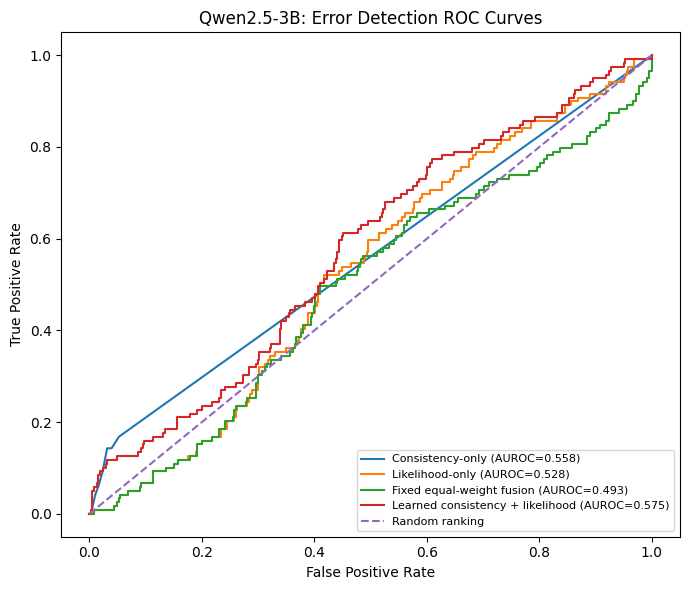

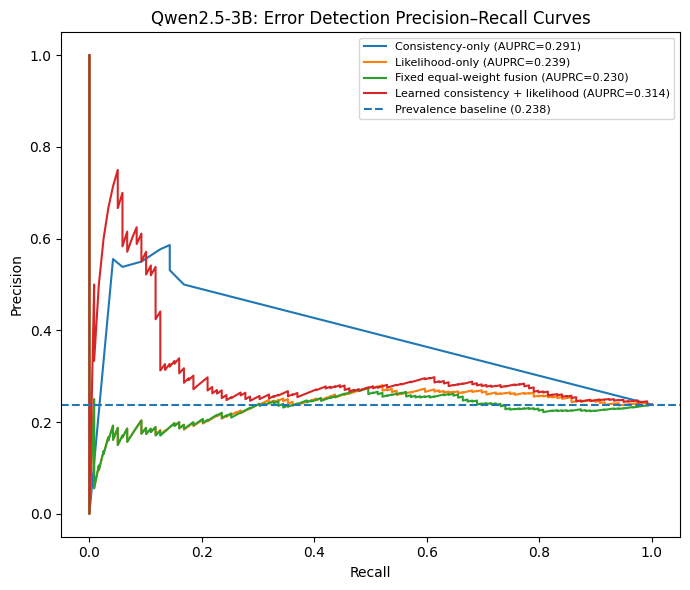

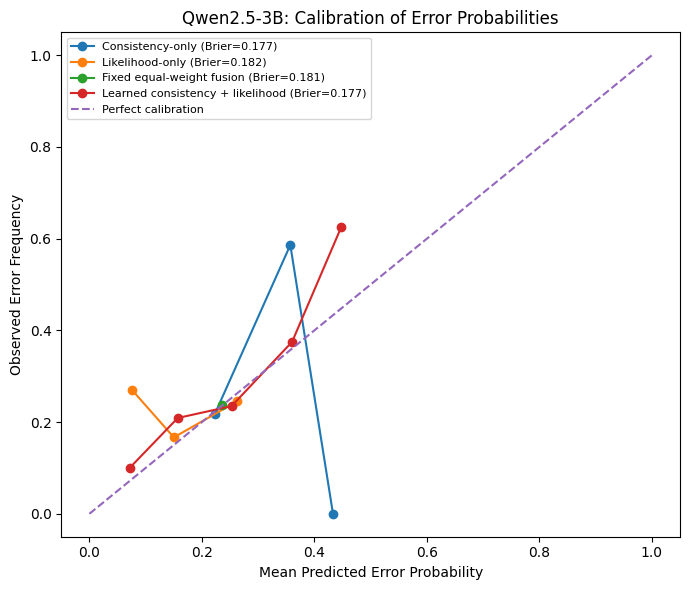

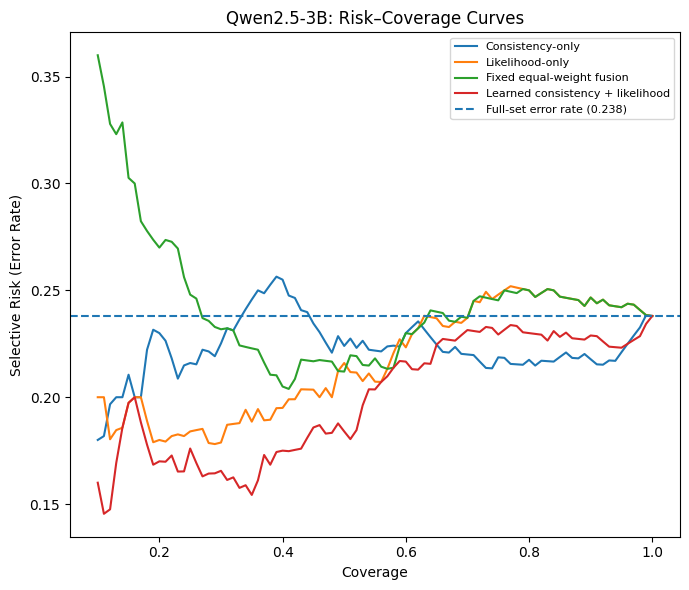

Figures saved in: /content/qwen3b_features/figures
Each figure is available as both PNG (300 dpi) and PDF.


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve, precision_recall_curve, roc_auc_score,
    average_precision_score, brier_score_loss
)
from sklearn.calibration import calibration_curve

OUT = "/content/qwen3b_features/figures"
os.makedirs(OUT, exist_ok=True)

y = test_df["is_error"].astype(int).to_numpy()
names = list(test_probabilities.keys())

def save_figure(filename):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, filename + ".png"), dpi=300,
                bbox_inches="tight")
    plt.savefig(os.path.join(OUT, filename + ".pdf"),
                bbox_inches="tight")
    plt.show()
    plt.close()

# Figure 1: ROC curves
plt.figure(figsize=(7, 6))
for name in names:
    p = np.asarray(test_probabilities[name])
    fpr, tpr, _ = roc_curve(y, p)
    auc = roc_auc_score(y, p)
    plt.plot(fpr, tpr, label=f"{name} (AUROC={auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Qwen2.5-3B: Error Detection ROC Curves")
plt.legend(loc="lower right", fontsize=8)
save_figure("qwen3b_roc")

# Figure 2: Precision-recall curves
plt.figure(figsize=(7, 6))
baseline = y.mean()

for name in names:
    p = np.asarray(test_probabilities[name])
    precision, recall, _ = precision_recall_curve(y, p)
    ap = average_precision_score(y, p)
    plt.plot(recall, precision, label=f"{name} (AUPRC={ap:.3f})")

plt.axhline(baseline, linestyle="--",
            label=f"Prevalence baseline ({baseline:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Qwen2.5-3B: Error Detection Precision–Recall Curves")
plt.legend(loc="best", fontsize=8)
save_figure("qwen3b_precision_recall")

# Figure 3: Calibration curves
plt.figure(figsize=(7, 6))
for name in names:
    p = np.asarray(test_probabilities[name])
    observed, predicted = calibration_curve(
        y, p, n_bins=10, strategy="uniform"
    )
    brier = brier_score_loss(y, p)
    plt.plot(predicted, observed, marker="o",
             label=f"{name} (Brier={brier:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean Predicted Error Probability")
plt.ylabel("Observed Error Frequency")
plt.title("Qwen2.5-3B: Calibration of Error Probabilities")
plt.legend(loc="best", fontsize=8)
save_figure("qwen3b_calibration")

# Figure 4: Risk–coverage curves
plt.figure(figsize=(7, 6))
coverage_grid = np.linspace(0.1, 1.0, 91)

for name in names:
    p = np.asarray(test_probabilities[name])
    order = np.argsort(p)  # retain lowest predicted-risk examples
    risks = []

    for coverage in coverage_grid:
        n_keep = max(1, int(np.ceil(coverage * len(y))))
        risks.append(y[order[:n_keep]].mean())

    plt.plot(coverage_grid, risks, label=name)

plt.axhline(y.mean(), linestyle="--",
            label=f"Full-set error rate ({y.mean():.3f})")
plt.xlabel("Coverage")
plt.ylabel("Selective Risk (Error Rate)")
plt.title("Qwen2.5-3B: Risk–Coverage Curves")
plt.legend(loc="best", fontsize=8)
save_figure("qwen3b_risk_coverage")

print("Figures saved in:", OUT)
print("Each figure is available as both PNG (300 dpi) and PDF.")

In [ ]:
import numpy as np
import pandas as pd

# Set these to the actual variables in your original notebook.
# test_df must contain the gold class and is_error columns.
# test_probabilities must contain error-risk scores for each method.

class_names = ["World", "Sports", "Business", "Sci/Tech"]

# Update these names to match your notebook's variables.
risk_columns = {
    "Consistency-only": consistency_risk,
    "Likelihood-only": likelihood_risk,
    "Fixed fusion": fixed_fusion_risk,
    "Learned fusion": learned_risk,
}

rows = []

for class_id, class_name in enumerate(class_names):
    class_mask = test_df["gold_label"].to_numpy() == class_id
    errors = test_df["is_error"].to_numpy().astype(bool)

    row = {
        "Model": "Qwen2.5-1.5B",
        "Class": class_name,
        "Correct / errors": (
            f"{int((class_mask & ~errors).sum())} / "
            f"{int((class_mask & errors).sum())}"
        ),
    }

    for method, scores in risk_columns.items():
        scores = np.asarray(scores)
        correct_mask = class_mask & ~errors
        error_mask = class_mask & errors

        row[method] = (
            f"{scores[correct_mask].mean():.4f} / "
            f"{scores[error_mask].mean():.4f}"
        )

    rows.append(row)

result = pd.DataFrame(rows)
print(result.to_string(index=False))
result.to_csv("qwen15b_classwise_mean_risk.csv", index=False)

NameError: name 'consistency_risk' is not defined

In [ ]:
# Inspect available variables without rerunning the model
for name in sorted(globals()):
    if any(term in name.lower() for term in [
        "test", "risk", "score", "prob", "feature", "error", "class"
    ]):
        obj = globals()[name]
        try:
            shape = obj.shape
        except AttributeError:
            try:
                shape = (len(obj),)
            except TypeError:
                shape = ""
        print(f"{name:40s} {type(obj).__name__:20s} {shape}")

FEATURES                                 list                 (5,)
X_test                                   ndarray              (500, 5)
accuracy_score                           function             
average_precision_score                  function             
brier_score_loss                         function             
candidate_label_scores                   function             
class_name                               str                  (8,)
class_names                              list                 (4,)
classification_report                    function             
classwise_df                             DataFrame            (16, 6)
consistency_features                     list                 (3,)
expected_calibration_error               function             
extract_features_for_article             function             
feature_sets                             dict                 (4,)
features                                 list                 (5,)
likelihood_featu

In [ ]:
import numpy as np
import pandas as pd

print("test_probabilities type:", type(test_probabilities))
print("test_df columns:", test_df.columns.tolist())

if isinstance(test_probabilities, dict):
    for name, values in test_probabilities.items():
        print(name, np.asarray(values).shape)

test_probabilities type: <class 'dict'>
test_df columns: ['row_id', 'text', 'label', 'label_name', 'is_error', 'vote_entropy', 'prompt_instability', 'invalid_rate', 'likelihood_entropy', 'likelihood_margin', 'base_prediction', 'base_predictions', 'alternative_predictions']
Consistency-only (500,)
Likelihood-only (500,)
Fixed equal-weight fusion (500,)
Learned consistency + likelihood (500,)


In [ ]:
# Map the four methods to the risk-score arrays in your session.
risk_arrays = {
    name: np.asarray(values).reshape(-1)
    for name, values in test_probabilities.items()
}

print("Available methods:", list(risk_arrays.keys()))
print("test_df columns:", test_df.columns.tolist())

Available methods: ['Consistency-only', 'Likelihood-only', 'Fixed equal-weight fusion', 'Learned consistency + likelihood']
test_df columns: ['row_id', 'text', 'label', 'label_name', 'is_error', 'vote_entropy', 'prompt_instability', 'invalid_rate', 'likelihood_entropy', 'likelihood_margin', 'base_prediction', 'base_predictions', 'alternative_predictions']


In [ ]:
import numpy as np
import pandas as pd

class_names = ["World", "Sports", "Business", "Sci/Tech"]

rows = []

for class_name in class_names:
    class_mask = test_df["label_name"].astype(str).str.strip().str.lower() == class_name.lower()
    error_mask = test_df["is_error"].astype(bool)

    row = {
        "Model": "Qwen2.5-1.5B",
        "Class": class_name,
        "Correct / errors": (
            f"{int((class_mask & ~error_mask).sum())} / "
            f"{int((class_mask & error_mask).sum())}"
        )
    }

    for method, scores in test_probabilities.items():
        scores = np.asarray(scores).reshape(-1)

        row[f"{method} (correct)"] = (
            scores[class_mask & ~error_mask].mean()
            if (class_mask & ~error_mask).any() else np.nan
        )
        row[f"{method} (errors)"] = (
            scores[class_mask & error_mask].mean()
            if (class_mask & error_mask).any() else np.nan
        )

    rows.append(row)

result = pd.DataFrame(rows)

# Display all risk means to four decimal places
display(result.round(4))

# Save the completed results
result.to_csv("qwen15b_classwise_mean_risk.csv", index=False)

print("Saved: qwen15b_classwise_mean_risk.csv")

,Model,Class,Correct / errors,Consistency-only (correct),Consistency-only (errors),Likelihood-only (correct),Likelihood-only (errors),Fixed equal-weight fusion (correct),Fixed equal-weight fusion (errors),Learned consistency + likelihood (correct),Learned consistency + likelihood (errors)
0,Qwen2.5-1.5B,World,114 / 11,0.2304,0.2231,0.2404,0.2640,0.2353,0.2358,0.2346,0.2513
1,Qwen2.5-1.5B,Sports,108 / 12,0.2251,0.2770,0.2052,0.2063,0.2348,0.2335,0.1935,0.2645
2,Qwen2.5-1.5B,Business,125 / 10,0.2247,0.2796,0.2711,0.2298,0.2360,0.2330,0.2611,0.2912
3,Qwen2.5-1.5B,Sci/Tech,34 / 86,0.2356,0.2352,0.2231,0.2520,0.2347,0.2353,0.2263,0.2521


Saved: qwen15b_classwise_mean_risk.csv
